In [1]:
# Import all required libraries
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import os, io, json, hashlib, datetime as dt
import requests
import pandas as pd

# ---------- 1.1 Ticker selection: source, retrieval date, extraction ----------
URL = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
headers = {"User-Agent": "Mozilla/5.0 (university coursework; contact: YOUR_EMAIL_HERE)"}   # <- put your email

os.makedirs("data/raw", exist_ok=True)

resp = requests.get(URL, headers=headers, timeout=30)
resp.raise_for_status()

# Retrieval date and exact time (UTC) recorded at the moment of download
retrieved_at = dt.datetime.now(dt.timezone.utc)
retrieval_date = retrieved_at.date().isoformat()

# Extract the first table (current constituents) with pandas, as the brief requires
tables = pd.read_html(io.StringIO(resp.text))
sp500 = tables[0].copy()
sp500["retrieval_date"] = retrieval_date

# Yahoo uses '-' where Wikipedia uses '.', e.g. BRK.B -> BRK-B
sp500["yf_ticker"] = sp500["Symbol"].str.replace(".", "-", regex=False)

# ---------- Checks on the extracted list ----------
assert sp500["Symbol"].notna().all(), "Blank symbols found"
assert sp500["Symbol"].is_unique, "Duplicate symbols found"
assert sp500["yf_ticker"].is_unique, "Duplicate Yahoo tickers after conversion"
print("Constituent rows:", len(sp500), "| unique tickers:", sp500["yf_ticker"].nunique())
print("Sectors:", sp500["GICS Sector"].nunique())
print("Tickers converted from '.' to '-':", (sp500["Symbol"] != sp500["yf_ticker"]).sum(),
      sp500.loc[sp500["Symbol"] != sp500["yf_ticker"], "Symbol"].tolist())

# ---------- Preserve the data ----------
sp500.to_csv("data/sp500_constituents.csv", index=False)           # extracted table
with open("data/raw/wikipedia_sp500_page.html", "w", encoding="utf-8") as f:
    f.write(resp.text)                                              # raw page snapshot (evidence of source)

source_meta = {
    "source_url": URL,
    "retrieval_date": retrieval_date,
    "retrieval_time_utc": retrieved_at.isoformat(timespec="seconds"),
    "http_status": resp.status_code,
    "page_last_modified_header": resp.headers.get("Last-Modified"),
    "tables_found_on_page": len(tables),
    "table_used": "tables[0] (current constituents)",
    "n_constituents": int(len(sp500)),
    "page_sha256": hashlib.sha256(resp.text.encode("utf-8")).hexdigest(),
    "pandas_version": pd.__version__,
}
with open("data/raw/constituents_metadata.json", "w") as f:
    json.dump(source_meta, f, indent=2)

print("\nRetrieval date:", retrieval_date)
print(json.dumps(source_meta, indent=2))
sp500[["Symbol", "yf_ticker", "Security", "GICS Sector", "retrieval_date"]].head()

Constituent rows: 503 | unique tickers: 503
Sectors: 11
Tickers converted from '.' to '-': 2 ['BRK.B', 'BF.B']

Retrieval date: 2026-11-24
{
  "source_url": "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies",
  "retrieval_date": "2026-11-24",
  "retrieval_time_utc": "2026-11-24T19:39:25+00:00",
  "http_status": 200,
  "page_last_modified_header": "Tue, 17 Nov 2026 19:28:35 GMT",
  "tables_found_on_page": 2,
  "table_used": "tables[0] (current constituents)",
  "n_constituents": 503,
  "page_sha256": "74fd5bbb3231860f0c5f5a689034625e0c005b0590578964e181960673c28317",
  "pandas_version": "2.2.3"
}


,Symbol,yf_ticker,Security,GICS Sector,retrieval_date
0,MMM,MMM,3M,Industrials,2026-11-24
1,AOS,AOS,A. O. Smith,Industrials,2026-11-24
2,ABT,ABT,Abbott Laboratories,Health Care,2026-11-24
3,ABBV,ABBV,AbbVie,Health Care,2026-11-24
4,ACN,ACN,Accenture,Information Technology,2026-11-24


In [3]:
start = '2021-01-01'
end = '2025-01-01'

# Extract the list of ticker symbols from the sp500 DataFrame
tickers = sp500["yf_ticker"].tolist()

df = yf.download(tickers, start=start, end=end, auto_adjust=False)['Adj Close']

print('Shape:', df.shape)
df.head()

[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['SNDK', 'Q', 'HONA', 'VYLR', 'FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Shape: (1005, 503)


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-04,114.009125,125.537117,84.219131,139.149994,97.269699,33.186359,232.029327,485.339996,132.622620,42.189487,...,26.124491,102.852097,54.757389,33.042770,93.015892,221.160004,95.016190,141.603394,378.130005,152.952011
2021-01-05,114.941277,127.089241,85.090019,148.300003,98.473198,33.319485,233.350266,485.690002,134.993164,43.010101,...,26.371330,106.017517,54.223648,34.635197,92.903938,229.750000,95.025177,144.053421,380.570007,154.017883
2021-01-06,118.093231,122.811188,84.354973,142.770004,98.268150,34.783871,235.901627,466.309998,135.601685,44.752834,...,26.506685,106.652519,55.424538,35.518970,96.822746,226.889999,95.545967,148.158386,394.820007,156.280533
2021-01-07,121.235611,127.001930,85.257797,151.270004,99.222054,34.460564,238.127274,477.739990,141.332764,44.355217,...,26.761477,105.594177,54.340416,35.797646,101.217422,239.479996,94.818649,147.280060,409.100006,156.140259
2021-01-08,122.100471,128.098114,85.705223,149.770004,99.498398,34.650742,238.995865,485.100006,142.359055,44.473652,...,26.578348,104.901443,54.840782,36.195763,100.191048,241.449997,96.210419,146.956467,405.470001,157.178116


In [6]:
# ---------- 1.2 Validation: transparent exclusions ----------
log = []
df1 = df.copy()
n0 = df1.shape[1]

df1.index = pd.to_datetime(df1.index)
df1 = df1.sort_index()

# 1. Duplicate dates: check, then remove if any exist
dups = df1.index.duplicated().sum()
print("duplicate dates:", dups)
if dups:
    df1 = df1.loc[~df1.index.duplicated(keep="first")]

# 2. No data at all
mask = df1.isna().all(axis=0)
log += [(t, "No data returned") for t in df1.columns[mask]]
df1 = df1.loc[:, ~mask]

# 3. Nonpositive prices
mask = (df1 <= 0).any(axis=0)
log += [(t, "Nonpositive price") for t in df1.columns[mask]]
df1 = df1.loc[:, ~mask]

# 4. Unequal / incomplete history (no filling)
n_missing = df1.isna().sum(axis=0)
mask = n_missing > 0
log += [(t, f"Missing {n_missing[t]} of {df1.shape[0]} days; first valid {df1[t].first_valid_index().date()}")
        for t in df1.columns[mask]]
df1 = df1.loc[:, ~mask]

# ---------- Exclusion log and summary ----------
exclusion_log = pd.DataFrame(log, columns=["ticker", "reason"])
exclusion_log["category"] = exclusion_log["reason"].str.replace(r"Missing .*", "Incomplete history", regex=True)
exclusion_log.to_csv("data/exclusion_log_validation.csv", index=False)

print("Before:", n0, "| After:", df1.shape[1], "| Excluded:", len(exclusion_log))
print(exclusion_log["category"].value_counts())
assert n0 == df1.shape[1] + len(exclusion_log), "Counts do not reconcile"
assert df1.isna().sum().sum() == 0, "NaNs remain"

# ---------- Period and calendar checks ----------
assert df1.index.min() >= pd.Timestamp(start) and df1.index.max() < pd.Timestamp(end), "Outside study period"
print("First/last trading date:", df1.index.min().date(), df1.index.max().date())

# Resolve the NameError: fetch the benchmark index directly here to perform the validation assertion
bench_df = yf.download("^GSPC", start=start, end=end, auto_adjust=False)['Adj Close']
bench_d = bench_df.squeeze().rename("^GSPC")
bench_d.index = pd.to_datetime(bench_d.index)
bench_d = bench_d.sort_index()

print("Dates match benchmark calendar:", df1.index.equals(bench_d.index))

duplicate dates: 0
Before: 503 | After: 488 | Excluded: 15
category
Incomplete history    10
No data returned       5
Name: count, dtype: int64
First/last trading date: 2021-01-04 2024-12-31


[*********************100%***********************]  1 of 1 completed

Dates match benchmark calendar: True


In [7]:
# Ensure the date index is in datetime format
df1.index = pd.to_datetime(df1.index)

# Sort the dates
df1 = df1.sort_index()

# Create the transposed version (tickers as rows, dates as columns) with datetime columns
adj_d = df1.T.copy()

print("Index type (tickers):", type(adj_d.index))
print("Columns type (dates):", type(adj_d.columns))
adj_d.head()

Index type (tickers): <class 'pandas.core.indexes.base.Index'>
Columns type (dates): <class 'pandas.core.indexes.datetimes.DatetimeIndex'>


Date,2021-01-04,2021-01-05,2021-01-06,2021-01-07,2021-01-08,2021-01-11,2021-01-12,2021-01-13,2021-01-14,2021-01-15,...,2024-12-17,2024-12-18,2024-12-19,2024-12-20,2024-12-23,2024-12-24,2024-12-26,2024-12-27,2024-12-30,2024-12-31
Ticker,,,,,,,,,,,,,,,,,,,,,
A,114.009125,114.941277,118.093231,121.235611,122.100471,123.147903,122.013977,122.023598,121.110672,121.283623,...,134.353806,130.957031,131.134262,132.433868,132.522507,133.999359,133.733521,133.447998,132.345261,132.511017
AAPL,125.537117,127.089241,122.811188,127.001930,128.098114,125.119987,124.945358,126.972832,125.052055,123.335052,...,251.462646,246.075882,247.802017,252.464630,253.238434,256.145142,256.958527,253.555862,250.192841,248.427032
ABBV,84.219131,85.090019,84.354973,85.257797,85.705223,87.103409,87.710617,89.843849,90.231834,89.334633,...,164.530701,162.316696,160.909485,164.718323,167.354492,168.864899,168.114410,166.998001,165.299973,166.707184
ABNB,139.149994,148.300003,142.770004,151.270004,149.770004,148.130005,160.800003,169.990005,180.500000,169.270004,...,132.240005,127.540001,129.350006,134.210007,134.520004,134.990005,135.320007,133.384995,131.809998,131.410004
ABT,97.269699,98.473198,98.268150,99.222054,99.498398,98.811966,97.028984,99.979805,98.493996,99.621780,...,108.486847,107.184517,107.653725,109.386993,109.463600,109.894524,110.382904,110.114777,108.017624,108.314484


In [8]:
# 1. Download benchmark data (S&P 500 Index)
bench_df = yf.download("^GSPC", start=start, end=end, auto_adjust=False)['Adj Close']

# Squeeze the downloaded DataFrame/Series to ensure it is 1-dimensional
bench_d = bench_df.squeeze().rename("^GSPC")
bench_d.index = pd.to_datetime(bench_d.index)
bench_d = bench_d.sort_index()

# 2. Resample stock prices (columns represent dates, so we must specify axis=1)
w_px = adj_d.resample("W-FRI", axis=1).last()
w_bench = bench_d.resample("W-FRI").last()

# Keep only complete weeks using the benchmark trading calendar
days = bench_d.index.to_series()
wk = days.resample("W-FRI").agg(["first", "last", "count"])
wk["complete"] = (wk["first"] <= wk.index - pd.Timedelta(days=3)) & \
                 (wk["last"]  >= wk.index - pd.Timedelta(days=1))
good_labels = wk.index[wk["complete"]]

# Filter to keep only complete weeks
w_px = w_px.loc[:, good_labels]
w_bench = w_bench.loc[good_labels]

print("Weekly Stock Prices Shape:", w_px.shape)
print("Weekly Benchmark Prices Shape:", w_bench.shape)

[*********************100%***********************]  1 of 1 completed

Weekly Stock Prices Shape: (488, 208)
Weekly Benchmark Prices Shape: (208,)



/tmp/ipykernel_4471/4100325610.py:10: FutureWarning: DataFrame.resample with axis=1 is deprecated. Do `frame.T.resample(...)` without axis instead.
  w_px = adj_d.resample("W-FRI", axis=1).last()


In [9]:
# Transpose weekly prices so dates are on the index (rows) and tickers are columns
w_px_df = w_px.T

# Calculate percent change along the row axis (dates index)
ret_w  = w_px_df.pct_change(fill_method=None).iloc[1:]
ret_bm = w_bench.pct_change(fill_method=None).iloc[1:]

# Ensure the date indexes match perfectly
assert ret_w.index.equals(ret_bm.index), "Weekly labels do not match!"

print("Returns aligned successfully!")
print("Weekly Stock Returns Shape (Dates x Tickers):", ret_w.shape)
print("Weekly Benchmark Returns Shape:", ret_bm.shape)

Returns aligned successfully!
Weekly Stock Returns Shape (Dates x Tickers): (207, 488)
Weekly Benchmark Returns Shape: (207,)


In [10]:
n_obs = ret_w.notna().sum()
mean_ret = ret_w.mean()                       # arithmetic mean, NaNs skipped (none if histories are complete)

print("weekly prices:", len(w_px.columns), "| weekly returns:", len(ret_w))
print("first/last return week:", ret_w.index[0].date(), ret_w.index[-1].date())
print("obs per share min/max:", n_obs.min(), n_obs.max())
print(mean_ret.describe())

# Independent check on one share using the corrected row-lookup (.loc)
t = mean_ret.index[0]
prices_t = w_px.loc[t]
manual = np.mean([prices_t.iloc[i] / prices_t.iloc[i-1] - 1 for i in range(1, len(prices_t))])
assert np.isclose(manual, mean_ret[t])

features = pd.DataFrame({"mean_weekly_return": mean_ret, "n_weekly_obs": n_obs})
features.to_csv("data/feature_mean_weekly_return.csv")
ret_w.to_csv("data/weekly_returns_shares.csv")

weekly prices: 208 | weekly returns: 207
first/last return week: 2021-01-15 2024-12-27
obs per share min/max: 207 207
count    488.000000
mean       0.002857
std        0.002646
min       -0.004468
25%        0.001182
50%        0.002629
75%        0.004207
max        0.017772
dtype: float64


In [11]:
rows = []
for t in ret_w.columns:
    pair = pd.concat([ret_w[t], ret_bm], axis=1, keys=["s", "m"]).dropna()  # no filling
    n = len(pair)
    cov = np.cov(pair["s"], pair["m"], ddof=1)[0, 1]
    var_m = pair["m"].var(ddof=1)            # same ddof as the covariance
    rows.append((t, cov / var_m, n, pair.index.min().date(), pair.index.max().date()))

beta_df = pd.DataFrame(rows, columns=["ticker", "beta", "n_aligned_weeks",
                                      "first_week", "last_week"]).set_index("ticker")

print("benchmark weekly returns:", len(ret_bm))
print("aligned obs per share min/max:", beta_df.n_aligned_weeks.min(), beta_df.n_aligned_weeks.max())
print(beta_df.beta.describe())

benchmark weekly returns: 207
aligned obs per share min/max: 207 207
count    488.000000
mean       0.973868
std        0.406550
min        0.055453
25%        0.666634
50%        0.950610
75%        1.179289
max        3.778560
Name: beta, dtype: float64


In [12]:
# ---------- 1.3.2 Weekly beta: verification, reporting and saving ----------

# (a) Week-label and sample checks
assert ret_w.index.equals(ret_bm.index), "Week labels differ"
assert ret_w.index.is_unique and ret_w.index.is_monotonic_increasing
assert (ret_w.index.dayofweek == 4).all(), "Labels must be Fridays"
assert not np.isinf(ret_w).any().any(), "Infinite returns"
assert ret_bm.index.max() < pd.Timestamp("2025-01-03"), "Final incomplete week must be excluded"

# Expected count: complete weeks ending 2021-01-08 ... 2024-12-27 = 208 prices -> 207 returns
expected_weeks = len(pd.date_range("2021-01-08", "2024-12-27", freq="W-FRI")) - 1
print("Expected return weeks:", expected_weeks, "| actual:", len(ret_bm))
assert len(ret_bm) == expected_weeks

# (b) Consecutive-week check: every return must span exactly one week (no multiweek change)
gaps = ret_w.index.to_series().diff().dropna().dt.days
assert (gaps == 7).all(), "Gap in week labels"
print("All week labels are exactly 7 days apart")

# (c) Price-basis check: benchmark Adj Close vs Close (verified, not assumed)
bench_close = yf.download("^GSPC", start=start, end=end, auto_adjust=False)["Close"].squeeze()
bench_close.index = pd.to_datetime(bench_close.index)
print("^GSPC Adj Close == Close on all days:", np.allclose(bench_d.values, bench_close.reindex(bench_d.index).values))

# (d) Beta check: cov/var must equal the OLS slope, computed on the aligned sample
slopes = {}
for t in ret_w.columns:
    pair = pd.concat([ret_w[t], ret_bm], axis=1, keys=["s", "m"], join="inner").dropna()
    slopes[t] = np.polyfit(pair["m"], pair["s"], 1)[0]
beta_df["ols_slope"] = pd.Series(slopes)
beta_df["abs_diff"] = (beta_df["beta"] - beta_df["ols_slope"]).abs()
assert beta_df["abs_diff"].max() < 1e-10
print("Max |cov/var - OLS slope|:", f"{beta_df['abs_diff'].max():.2e}")

b_self = np.cov(ret_bm, ret_bm, ddof=1)[0, 1] / ret_bm.var(ddof=1)
print("Benchmark self-beta (should be 1):", round(b_self, 12))

# (e) Reporting
print("\nBenchmark weekly returns:", len(ret_bm),
      "| first:", ret_bm.index.min().date(), "| last:", ret_bm.index.max().date())
print("Shares with beta:", beta_df["beta"].notna().sum(), "/", len(beta_df))
print("Aligned weeks per share (min/max):", beta_df.n_aligned_weeks.min(), "/", beta_df.n_aligned_weeks.max())
print("Shares with the full", len(ret_bm), "weeks:", (beta_df.n_aligned_weeks == len(ret_bm)).sum())
print("\nBeta summary:\n", beta_df["beta"].describe().round(4))

# (f) Extremes flagged for review (kept, not removed)
print("\nLowest 5 betas:\n", beta_df["beta"].nsmallest(5).round(3))
print("\nHighest 5 betas:\n", beta_df["beta"].nlargest(5).round(3))

# (g) Save
beta_df[["beta", "n_aligned_weeks", "first_week", "last_week"]].to_csv("data/feature_weekly_beta.csv")
features = features.join(beta_df["beta"].rename("weekly_beta"))   # mean return + beta for clustering
features.to_csv("data/clustering_features.csv")
print("\nSaved. Feature table shape:", features.shape)

[*********************100%***********************]  1 of 1 completed

Expected return weeks: 207 | actual: 207
All week labels are exactly 7 days apart
^GSPC Adj Close == Close on all days: True


Max |cov/var - OLS slope|: 2.22e-15
Benchmark self-beta (should be 1): 1.0

Benchmark weekly returns: 207 | first: 2021-01-15 | last: 2024-12-27
Shares with beta: 488 / 488
Aligned weeks per share (min/max): 207 / 207
Shares with the full 207 weeks: 488

Beta summary:
 count    488.0000
mean       0.9739
std        0.4066
min        0.0555
25%        0.6666
50%        0.9506
75%        1.1793
max        3.7786
Name: beta, dtype: float64

Lowest 5 betas:
 ticker
GIS    0.055
SJM    0.176
MRK    0.198
BMY    0.225
KHC    0.227
Name: beta, dtype: float64

Highest 5 betas:
 ticker
CVNA    3.779
XYZ     2.505
COHR    2.139
NVDA    2.126
TWLO    2.073
Name: beta, dtype: float64

Saved. Feature table shape: (488, 3)


In [13]:
# Large weekly moves that could indicate unadjusted splits or data errors
big = ret_w.abs().stack()
big = big[big > 0.40].sort_values(ascending=False)
print("Weekly |returns| > 40%:", len(big))
print(big.head(10))

# Compare Adj Close vs Close for a few known splitters (NVDA 2021 and 2024, AMZN 2022, TSLA 2022, GOOGL 2022)
chk = yf.download(["NVDA","AMZN","TSLA","GOOGL"], start=start, end=end, auto_adjust=False)
for t in ["NVDA","AMZN","TSLA","GOOGL"]:
    ratio = (chk["Close"][t] / chk["Adj Close"][t])
    print(t, "Close/Adj Close ratio range:", round(ratio.min(), 2), "-", round(ratio.max(), 2))

[                       0%                       ]

Weekly |returns| > 40%: 18
Date        Ticker
2023-02-03  CVNA      0.859717
2024-11-22  SMCI      0.784177
2022-08-05  CVNA      0.611664
2024-11-15  BE        0.605163
2023-01-13  CVNA      0.591837
2021-10-29  BE        0.548291
2021-03-26  SKYD      0.504571
2024-04-12  GL        0.455141
2022-03-04  OXY       0.449406
2024-11-01  SMCI      0.448911
dtype: float64


[*********************100%***********************]  4 of 4 completed

NVDA Close/Adj Close ratio range: 1.0 - 1.01
AMZN Close/Adj Close ratio range: 1.0 - 1.0
TSLA Close/Adj Close ratio range: 1.0 - 1.0
GOOGL Close/Adj Close ratio range: 1.01 - 1.01


In [14]:
import os; os.makedirs("data", exist_ok=True)

# 1.4 needs unadjusted Close and Volume (earlier cells only kept Adj Close)
raw   = yf.download(list(df1.columns), start=start, end=end, auto_adjust=False)
close = raw["Close"].reindex(index=df1.index, columns=df1.columns)
vol   = raw["Volume"].reindex(index=df1.index, columns=df1.columns)
close.index = pd.to_datetime(close.index); vol.index = pd.to_datetime(vol.index)

# Validation (reported, nothing filled)
print("duplicate dates   :", close.index.duplicated().sum())
print("NaN Close / Volume:", close.isna().sum().sum(), "/", vol.isna().sum().sum())
print("nonpositive Close :", (close <= 0).sum().sum())
print("negative Volume   :", (vol < 0).sum().sum())
zv = (vol == 0).sum()
print("zero-volume days  :", int(zv.sum()), "across", int((zv > 0).sum()), "shares")

# Observation date = final date on which every retained share and the benchmark has data
common   = close.notna().all(axis=1) & vol.notna().all(axis=1) & close.index.isin(bench_d.index)
obs_date = close.index[common][-1]
print("Observation date:", obs_date.date())

[*********************100%***********************]  488 of 488 completed


duplicate dates   : 0
NaN Close / Volume: 0 / 0
nonpositive Close : 0
negative Volume   : 0
zero-volume days  : 451 across 2 shares
Observation date: 2024-12-31


In [15]:
W_BASE, W_WIN, MULT = 20, 60, 2

# Mean of the 20 sessions BEFORE each day (shift(1) excludes the tested day); needs a full 20
base_mean = vol.shift(1).rolling(W_BASE, min_periods=W_BASE).mean()
threshold = MULT * base_mean                    # separate for every share and day
event     = (vol > threshold).loc[:obs_date]    # strictly greater than 2x

# 1.4.1 Recency: latest event in the whole valid history, calendar days to obs_date
last_ev = event.apply(lambda c: c.index[c.values][-1] if c.any() else pd.NaT)
recency = (obs_date - last_ev).dt.days          # NaN if no event (never filled with 0)

# 1.4.2 Frequency: event days in the latest 60 trading sessions
win_idx   = close.loc[:obs_date].index[-W_WIN:]
assert len(win_idx) == W_WIN
frequency = event.loc[win_idx].sum().astype(int)

# 1.4.3 Monetary: sum of Close x Volume over the same 60 sessions (USD)
monetary = (close.loc[win_idx] * vol.loc[win_idx]).sum()

rfm = pd.DataFrame({"last_event_date": last_ev, "R_recency_days": recency,
                    "F_frequency": frequency, "M_usd": monetary})
print("60-session window:", win_idx[0].date(), "->", win_idx[-1].date())
print(rfm.describe().round(2))

60-session window: 2024-10-07 -> 2024-12-31
                     last_event_date  R_recency_days  F_frequency  \
count                            488          488.00       488.00   
mean   2024-12-10 14:39:20.655737600           20.39         2.99   
min              2024-05-23 00:00:00            4.00         0.00   
25%              2024-12-16 00:00:00           11.00         2.00   
50%              2024-12-20 00:00:00           11.00         3.00   
75%              2024-12-20 00:00:00           15.00         4.00   
max              2024-12-27 00:00:00          222.00         8.00   
std                              NaN           21.30         1.33   

              M_usd  
count  4.880000e+02  
mean   3.930290e+10  
min    1.297483e+09  
25%    1.023194e+10  
50%    1.668382e+10  
75%    3.210048e+10  
max    1.847697e+12  
std    1.288833e+11  


In [16]:
# ===== 1.5 Metric interpretation and supporting evidence (FULL, STANDALONE) =====
# Works from a fresh Colab session. It uses your saved files / notebook variables if they exist and
# otherwise rebuilds the constituent list and the 1.2 exclusion log itself (same rules as your cells 1 and 3).
import os, io, datetime as dt, numpy as np, pandas as pd, yfinance as yf
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
os.makedirs("data", exist_ok=True)
START, END = "2021-01-01", "2025-01-01"
W_BASE, W_WIN, MULT = 20, 60, 2

# ---------- 0. Inputs ----------
def load(fname, var, **kw):                 # saved file first, then the notebook variable of the same name
    if os.path.exists(f"data/{fname}"): return pd.read_csv(f"data/{fname}", **kw)
    if globals().get(var) is not None: return globals()[var].copy()
    raise FileNotFoundError(fname)

def rebuild_constituents_and_exclusions():  # = your cells 1 and 3, in one place
    import requests
    print("Saved list / exclusion log not found: rebuilding them from Wikipedia and Yahoo Finance (about 1-2 minutes) ...")
    url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
    resp = requests.get(url, headers={"User-Agent": "Mozilla/5.0 (university coursework)"}, timeout=30); resp.raise_for_status()
    sp = pd.read_html(io.StringIO(resp.text))[0].copy()
    sp["retrieval_date"] = dt.date.today().isoformat()
    sp["yf_ticker"] = sp["Symbol"].str.replace(".", "-", regex=False)
    adj = yf.download(sp["yf_ticker"].tolist(), start=START, end=END, auto_adjust=False, progress=False)["Adj Close"]
    log = []
    m = adj.isna().all(axis=0);  log += [(t, "No data returned") for t in adj.columns[m]];  adj = adj.loc[:, ~m]
    m = (adj <= 0).any(axis=0);  log += [(t, "Nonpositive price") for t in adj.columns[m]];  adj = adj.loc[:, ~m]
    miss = adj.isna().sum(axis=0); m = miss > 0
    log += [(t, f"Missing {miss[t]} of {adj.shape[0]} days") for t in adj.columns[m]]
    excl = pd.DataFrame(log, columns=["ticker", "reason"])
    sp.to_csv("data/sp500_constituents.csv", index=False); excl.to_csv("data/exclusion_log_validation.csv", index=False)
    print(f"Rebuilt: {len(sp)} tickers, {len(excl)} excluded, {len(sp) - len(excl)} retained (your earlier run: 503 / 15 / 488)")
    return sp, excl

try:
    sp500 = load("sp500_constituents.csv", "sp500")
    exclusion_log = load("exclusion_log_validation.csv", "exclusion_log")
except FileNotFoundError:
    sp500, exclusion_log = rebuild_constituents_and_exclusions()
retained = [t for t in sp500["yf_ticker"] if t not in set(exclusion_log["ticker"])]
print(f"{len(sp500)} listed | {len(exclusion_log)} excluded in 1.2 | {len(retained)} retained")

raw = yf.download(retained, start=START, end=END, auto_adjust=False, progress=False)
close = raw["Close"].reindex(columns=retained); vol = raw["Volume"].reindex(columns=retained)
close.index = pd.to_datetime(close.index); vol.index = pd.to_datetime(vol.index)
bench = yf.download("^GSPC", start=START, end=END, auto_adjust=False, progress=False)["Close"].squeeze()
bench.index = pd.to_datetime(bench.index)
print("Close/Volume shape:", close.shape, "| benchmark days:", len(bench))

# ---------- 1. Recompute RFM exactly as in 1.4 ----------
common_ok = close.notna().all(axis=1) & vol.notna().all(axis=1) & close.index.isin(bench.index)
obs_date = close.index[common_ok][-1]
base_mean = vol.shift(1).rolling(W_BASE, min_periods=W_BASE).mean()   # 20 sessions BEFORE each day
threshold = MULT * base_mean
event = (vol > threshold).loc[:obs_date]
last_ev = event.apply(lambda c: c.index[c.values][-1] if c.any() else pd.NaT)
win_idx = close.loc[:obs_date].index[-W_WIN:]
rfm = pd.DataFrame({"last_event_date": last_ev,
                    "R_recency_days": (obs_date - last_ev).dt.days,
                    "F_frequency": event.loc[win_idx].sum().astype(int),
                    "M_usd": (close.loc[win_idx] * vol.loc[win_idx]).sum()})
print("Observation date:", obs_date.date(), "| window:", win_idx[0].date(), "->", win_idx[-1].date(), f"({len(win_idx)} sessions)")
print(rfm.describe().round(2))

try:
    feats = load("clustering_features.csv", "features", index_col=0)
    risk_idx = feats[["mean_weekly_return", "weekly_beta"]].reindex(retained).dropna().index
except Exception:
    print("NOTE: clustering_features.csv / 'features' not found (1.3 not run in this session). The risk matrix is assumed to hold all retained shares.")
    risk_idx = pd.Index(retained)
act_df = rfm.dropna(subset=["R_recency_days"])[["R_recency_days", "F_frequency", "M_usd"]]   # raw units
PRE = close.loc[:obs_date].index
no_event = rfm.index[rfm["last_event_date"].isna()]

# ---------- A. Worked example (recomputed with a plain loop) ----------
EX = "AAPL"                                              # change to any retained ticker
if EX not in rfm.index: EX = rfm.index[0]
ex_name = sp500.loc[sp500["yf_ticker"] == EX, "Security"].iloc[0]
d = pd.DataFrame({"Close": close[EX], "Volume": vol[EX], "baseline_mean_20": base_mean[EX],
                  "threshold_2x": threshold[EX]}).loc[:obs_date]
d["high_volume_day"] = event[EX]; d["volume_to_baseline"] = d["Volume"] / d["baseline_mean_20"]
d["daily_value_usd"] = d["Close"] * d["Volume"]
dw = d.loc[win_idx]

v = vol[EX].loc[:obs_date].to_numpy(float)
manual = np.zeros(len(v), bool)
for i in range(W_BASE, len(v)):
    manual[i] = v[i] > MULT * v[i - W_BASE:i].mean()     # days i-20..i-1: the tested day is excluded
ev_days = PRE[manual]
R_m = (obs_date - ev_days[-1]).days if len(ev_days) else np.nan
F_m = int(manual[-W_WIN:].sum())
M_m = float((close[EX].loc[win_idx].to_numpy(float) * vol[EX].loc[win_idx].to_numpy(float)).sum())
same = (R_m == rfm.loc[EX, "R_recency_days"]) and F_m == rfm.loc[EX, "F_frequency"] and np.isclose(M_m, rfm.loc[EX, "M_usd"])

print(f"\n=== WORKED EXAMPLE: {EX} ({ex_name}) ===")
print("High-volume days inside the window (volume > 2 x mean of the 20 sessions before the day):")
print(dw.loc[dw["high_volume_day"], ["Volume", "baseline_mean_20", "threshold_2x", "volume_to_baseline"]].round(2).to_string())
print(f"\nLatest high-volume day: {ev_days[-1].date() if len(ev_days) else 'none'}")
print(f"R = {obs_date.date()} - {ev_days[-1].date() if len(ev_days) else 'none'} = {R_m} calendar days")
print(f"F = {F_m} high-volume days in the window")
print("\nFirst and last 3 sessions of the window:")
print(pd.concat([dw.head(3), dw.tail(3)])[["Close", "Volume", "daily_value_usd"]].round(2).to_string())
print(f"M = sum of the {W_WIN} daily values = ${M_m:,.0f} (${M_m/1e9:,.2f} billion)")
print("Loop recomputation matches the vectorised R, F, M:", "YES" if same else "NO - CHECK")
dw.to_csv("data/rfm_worked_example.csv")

# ---------- B. Validation checks (never stops the cell; read the PASS/FAIL lines) ----------
checks = []
def chk(name, fn, detail=""):
    try: ok = bool(fn())
    except Exception as e: ok, detail = False, f"error: {e}"
    checks.append({"check": name, "result": "PASS" if ok else "FAIL", "detail": detail})
    print(("PASS  " if ok else "FAIL  ") + name + (f"  [{detail}]" if detail else ""))

print("\n=== VALIDATION CHECKS ===")
vp, cp, thr = vol.loc[:obs_date], close.loc[:obs_date], threshold.loc[:obs_date]
chk("Close and Volume have no missing values", lambda: cp.notna().all().all() and vp.notna().all().all())
chk("Close > 0 and Volume >= 0 everywhere", lambda: (cp > 0).all().all() and (vp >= 0).all().all())
chk("Observation date = last date with data for every share and the benchmark",
    lambda: obs_date == close.index[-1] and obs_date in bench.index, str(obs_date.date()))
chk(f"Window is exactly {W_WIN} sessions ending on the observation date",
    lambda: len(win_idx) == W_WIN and win_idx[-1] == obs_date, f"{win_idx[0].date()} -> {win_idx[-1].date()}")
chk(f"First {W_BASE} sessions are never tested (no full 20-session baseline)",
    lambda: thr.iloc[:W_BASE].isna().all().all() and thr.iloc[W_BASE].notna().all(), f"first tested day {PRE[W_BASE].date()}")
chk(f"Every day of the {W_WIN}-session window has a full {W_BASE}-session baseline",
    lambda: threshold.loc[win_idx].notna().all().all(), f"{int((PRE < win_idx[0]).sum())} sessions precede the window")

def align_test(N=2000):
    rng = np.random.default_rng(42); bad = 0
    for _ in range(N):
        j, i = rng.integers(0, vp.shape[1]), rng.integers(W_BASE, len(vp))
        m = MULT * vp.iloc[i - W_BASE:i, j].mean()       # explicit slice, tested day excluded
        bad += (not np.isclose(thr.iloc[i, j], m, rtol=1e-9)) or \
               ((vp.iloc[i, j] > m) != event.iloc[i, j] and not np.isclose(vp.iloc[i, j], m, rtol=1e-9))
    return bad == 0
chk("Threshold alignment: 2000 random share-days match an explicit 20-session slice", align_test)
ties = (vp == thr)
chk("Strict inequality: volume exactly equal to the threshold is not an event",
    lambda: not (event & ties).any().any(), f"{int(ties.sum().sum())} tie days")
print(f"INFO  zero thresholds: {int((thr == 0).sum().sum())} share-days | zero-volume days: {int((vp == 0).sum().sum())} across {int(((vp == 0).sum() > 0).sum())} shares")

chk("No-event shares have a missing R (never 0)",
    lambda: rfm.loc[no_event, "R_recency_days"].isna().all(), f"{len(no_event)} shares with no event")
chk("R = 0 only where there is an event on the observation date",
    lambda: int((rfm["R_recency_days"] == 0).sum()) == int(event.loc[obs_date].sum()), f"{int((rfm['R_recency_days'] == 0).sum())} shares")
def toy_test():
    toy = pd.DataFrame({"flat": 1e6, "spike": 1e6}, index=pd.bdate_range("2024-01-01", periods=40))
    toy.loc[toy.index[30], "spike"] = 5e6
    ev = toy > MULT * toy.shift(1).rolling(W_BASE, min_periods=W_BASE).mean()
    R = (toy.index[-1] - ev.apply(lambda c: c.index[c.values][-1] if c.any() else pd.NaT)).dt.days
    return np.isnan(R["flat"]) and R["spike"] == (toy.index[-1] - toy.index[30]).days
chk("Toy test: no event gives a missing R, one event gives a number", toy_test)
gap = (obs_date - PRE[-W_WIN - 1]).days; has = rfm["R_recency_days"].notna()
chk("F = 0 exactly when the latest event is before the window",
    lambda: ((rfm.loc[has, "F_frequency"] == 0) == (rfm.loc[has, "R_recency_days"] >= gap)).all(), f"R >= {gap} days")
common = risk_idx.intersection(act_df.index)
chk("Shares missing from the activity matrix are exactly the no-event shares",
    lambda: set(rfm.index) - set(act_df.index) == set(no_event), f"{len(risk_idx)} risk, {len(act_df)} activity")
chk("Common valid share set exists", lambda: len(common) > 0, f"{len(common)} shares")
checks = pd.DataFrame(checks); checks.to_csv("data/rfm_validation_checks.csv", index=False)
print(f"\n{(checks['result'] == 'PASS').sum()} of {len(checks)} checks passed")

# ---------- C. Inclusion / exclusion log ----------
excl = exclusion_log.set_index("ticker")["reason"]
rows = []
for t, nm_ in zip(sp500["yf_ticker"], sp500["Security"]):
    if t in excl.index:   stage, status, why = "1.2 validation", "Excluded", excl[t]
    elif t in no_event:   stage, status, why = "1.4.1 Recency", "Excluded from RFM", "No qualifying high-volume day"
    else:                 stage, status, why = "-", "Included", "-"
    rows.append((t, nm_, stage, status, why, t in common))
inc_log = pd.DataFrame(rows, columns=["ticker", "security", "stage", "status", "reason", "in_common_set"])
inc_log.to_csv("data/rfm_inclusion_log.csv", index=False)
funnel = pd.DataFrame([("Tickers on the constituent list", len(sp500)),
                       ("Excluded in validation (1.2)", -len(exclusion_log)),
                       ("Retained shares", len(retained)),
                       ("Excluded from RFM: no qualifying high-volume day (1.4.1)", -len(no_event)),
                       ("Shares in the activity (RFM) matrix", len(act_df)),
                       ("Shares in the risk matrix", len(risk_idx)),
                       ("Common valid share set", len(common))], columns=["step", "shares"])
print("\n=== INCLUSION / EXCLUSION FUNNEL ===\n", funnel.to_string(index=False))
print("\nExcluded tickers:\n", inc_log.loc[inc_log["status"] != "Included", ["ticker", "security", "stage", "reason"]].to_string(index=False))

# ---------- D. Feature summaries ----------
feat = pd.DataFrame({"R_recency_days": rfm["R_recency_days"], "F_frequency": rfm["F_frequency"],
                     "M_usd_billion": rfm["M_usd"] / 1e9, "logM": np.log1p(rfm["M_usd"])})
summ = feat.describe(percentiles=[.25, .5, .75]).T; summ["skew"] = feat.skew()
print("\n=== FEATURE SUMMARY ===\n", summ.round(2).to_string())
rfm.to_csv("data/rfm_features.csv"); summ.to_csv("data/rfm_feature_summary.csv")
names = sp500.set_index("yf_ticker")["Security"]
print("\nHighest M ($ billion):\n", rfm["M_usd"].nlargest(5).div(1e9).round(1).rename("M_usd_billion").to_frame().join(names).to_string())
print("\nLowest M ($ billion):\n", rfm["M_usd"].nsmallest(5).div(1e9).round(1).rename("M_usd_billion").to_frame().join(names).to_string())
print("\nMost common latest-event dates (shares):\n", rfm["last_event_date"].value_counts().head(3).to_string())
print("Shares with R = 11:", int((rfm["R_recency_days"] == 11).sum()), "| shares with F = 0:", int((rfm["F_frequency"] == 0).sum()))
print("\nSaved in data/: rfm_features, rfm_feature_summary, rfm_worked_example, rfm_validation_checks, rfm_inclusion_log (.csv)")

503 listed | 15 excluded in 1.2 | 488 retained
Close/Volume shape: (1005, 488) | benchmark days: 1005
Observation date: 2024-12-31 | window: 2024-10-07 -> 2024-12-31 (60 sessions)
                     last_event_date  R_recency_days  F_frequency         M_usd
count                            488          488.00       488.00  4.880000e+02
mean   2024-12-10 14:39:20.655737600           20.39         2.99  3.930290e+10
min              2024-05-23 00:00:00            4.00         0.00  1.297483e+09
25%              2024-12-16 00:00:00           11.00         2.00  1.023194e+10
50%              2024-12-20 00:00:00           11.00         3.00  1.668382e+10
75%              2024-12-20 00:00:00           15.00         4.00  3.210048e+10
max              2024-12-27 00:00:00          222.00         8.00  1.847697e+12
std                              NaN           21.30         1.33  1.288833e+11

=== WORKED EXAMPLE: AAPL (Apple Inc.) ===
High-volume days inside the window (volume > 2 x mean of 

risk matrix: (488, 2) | activity matrix: (488, 3)
                      skew     min  median     max  n_IQR_outliers
mean_weekly_return  0.8692 -0.0045  0.0026  0.0178              15
weekly_beta         1.1043  0.0555  0.9506  3.7786              10
                 skew           min        median           max  n_IQR_outliers
R_recency_days   3.65  4.000000e+00  1.100000e+01  2.220000e+02             113
F_frequency      0.43  0.000000e+00  3.000000e+00  8.000000e+00               2
M_usd           11.71  1.297483e+09  1.668382e+10  1.847697e+12              45


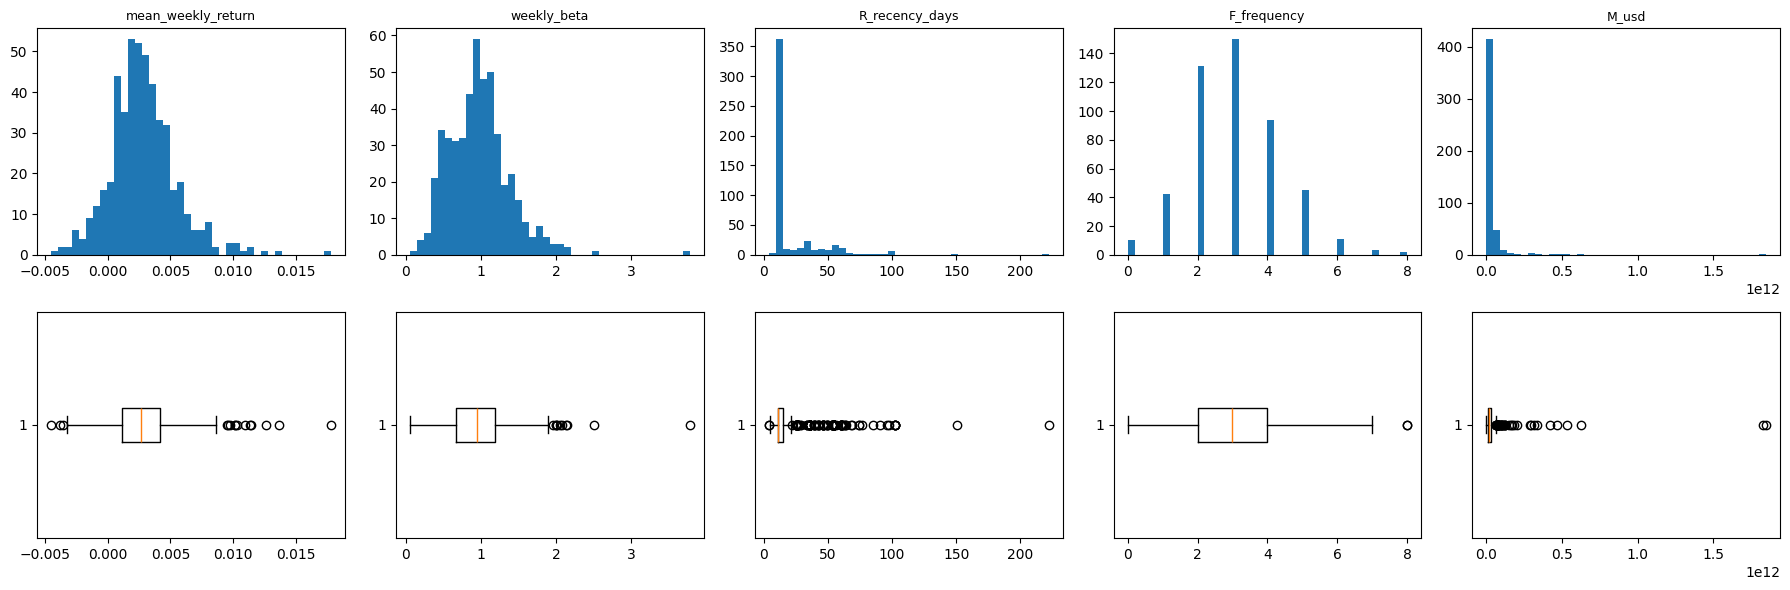

In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Matrix 1: risk and return (all 488 shares)
risk_df = features[["mean_weekly_return", "weekly_beta"]].copy()

# Matrix 2: trading activity (only shares with a valid Recency; the rest are logged exclusions from 1.4.1)
rfm_valid = rfm.dropna(subset=["R_recency_days"])
act_df = rfm_valid[["R_recency_days", "F_frequency", "M_usd"]].copy()
print("risk matrix:", risk_df.shape, "| activity matrix:", act_df.shape)

# Inspect skew and outliers (raw)
def inspect(df):
    q1, q3 = df.quantile(.25), df.quantile(.75); iqr = q3 - q1
    out = ((df < q1 - 1.5*iqr) | (df > q3 + 1.5*iqr)).sum()
    return pd.DataFrame({"skew": df.skew(), "min": df.min(), "median": df.median(),
                         "max": df.max(), "n_IQR_outliers": out})
print(inspect(risk_df).round(4)); print(inspect(act_df).round(2))

fig, ax = plt.subplots(2, 5, figsize=(18, 6))
for j, c in enumerate(list(risk_df.columns) + list(act_df.columns)):
    s = risk_df[c] if c in risk_df else act_df[c]
    ax[0, j].hist(s, bins=40); ax[0, j].set_title(c, fontsize=9)
    ax[1, j].boxplot(s, vert=False)
plt.tight_layout(); plt.show()

In [18]:
# log1p on M only (as required); R and F are left on their original scales (justified below)
act_t = act_df.copy()
act_t["M_usd"] = np.log1p(act_t["M_usd"])
print("skew of M before/after log1p:", round(act_df["M_usd"].skew(), 2), "->", round(act_t["M_usd"].skew(), 2))

# Standardise each matrix separately (z-scores: mean 0, sd 1)
X_risk = pd.DataFrame(StandardScaler().fit_transform(risk_df),
                      index=risk_df.index, columns=risk_df.columns)
X_act  = pd.DataFrame(StandardScaler().fit_transform(act_t),
                      index=act_t.index, columns=act_t.columns)
print(X_risk.describe().loc[["mean", "std"]].round(3)); print(X_act.describe().loc[["mean", "std"]].round(3))

# Four baseline solutions: {K-means, agglomerative} x {risk, activity}
K = 4   # provisional baseline; the choice of k is justified in the model-selection task
labels, sil = {}, {}
for name, X in [("risk", X_risk), ("activity", X_act)]:
    labels[(name, "kmeans")] = KMeans(n_clusters=K, n_init=20, random_state=42).fit_predict(X)
    labels[(name, "agglom")] = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X)
for (name, algo), lab in labels.items():
    X = X_risk if name == "risk" else X_act
    sil[(name, algo)] = silhouette_score(X, lab)
    print(f"{name:9s} {algo:7s} sizes={np.bincount(lab)}  silhouette={sil[(name, algo)]:.3f}")

# Store labels (kept in separate frames; no combined score)
risk_labels = pd.DataFrame({"kmeans": labels[("risk", "kmeans")], "agglom": labels[("risk", "agglom")]}, index=X_risk.index)
act_labels  = pd.DataFrame({"kmeans": labels[("activity", "kmeans")], "agglom": labels[("activity", "agglom")]}, index=X_act.index)
risk_labels.to_csv("data/baseline_labels_risk.csv"); act_labels.to_csv("data/baseline_labels_activity.csv")
X_risk.to_csv("data/X_risk_scaled.csv"); X_act.to_csv("data/X_activity_scaled.csv")

skew of M before/after log1p: 11.71 -> 1.08
      mean_weekly_return  weekly_beta
mean               0.000        0.000
std                1.001        1.001
      R_recency_days  F_frequency  M_usd
mean          -0.000       -0.000 -0.000
std            1.001        1.001  1.001
risk      kmeans  sizes=[132 154 162  40]  silhouette=0.326
risk      agglom  sizes=[184  92 114  98]  silhouette=0.265
activity  kmeans  sizes=[122  61 214  91]  silhouette=0.341
activity  agglom  sizes=[ 86 137 179  86]  silhouette=0.251


risk: cophenetic correlation = 0.463
activity: cophenetic correlation = 0.481


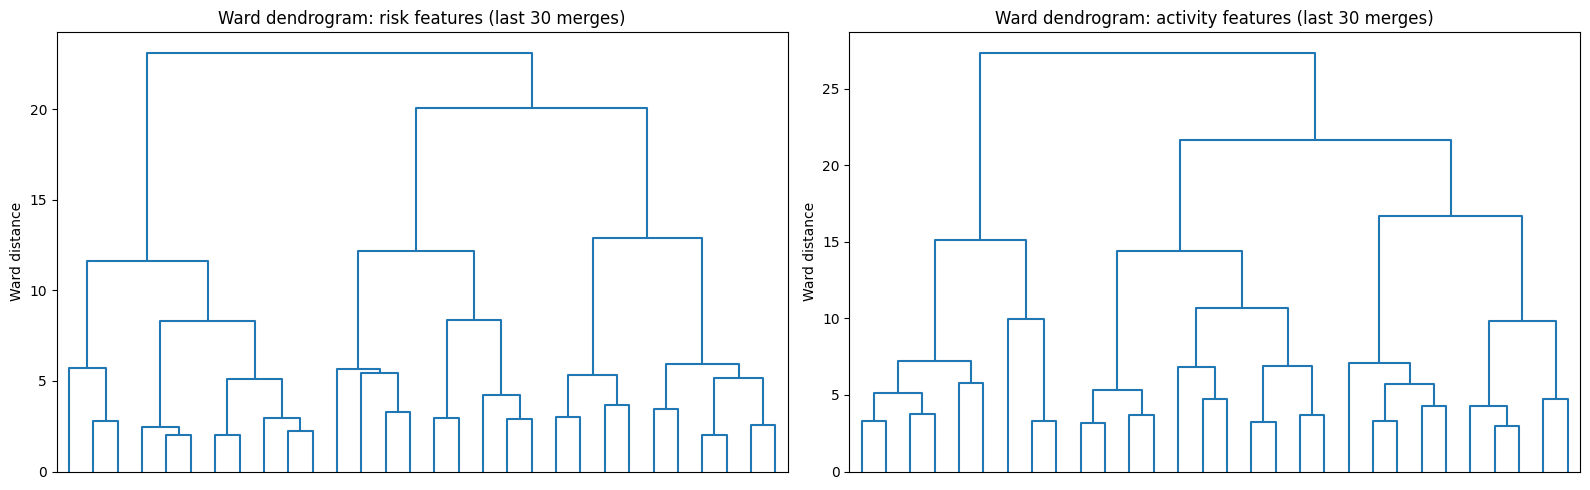

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist

# Load datasets if they are missing from namespace
if 'X_risk' not in globals():
    try:
        X_risk = pd.read_csv("data/X_risk_scaled.csv", index_col=0)
        X_act = pd.read_csv("data/X_activity_scaled.csv", index_col=0)
        features = pd.read_csv("data/clustering_features.csv", index_col=0)
        risk_df = features[["mean_weekly_return", "weekly_beta"]].copy()

        # Load rfm to reconstruct act_df
        # (We drop rows matching X_act's index to align the active frames)
        X_act.index = X_act.index.astype(str)
        risk_df.index = risk_df.index.astype(str)
        X_risk.index = X_risk.index.astype(str)

        # Reconstruct act_df (RFM activity metrics)
        # If the original raw activity file isn't available, we can use the scaled X_act as a backup
        act_df = X_act.copy()
    except Exception as e:
        print("Error reloading datasets from CSV files. Please make sure to run the previous cells first.", e)

mats ={"risk": (X_risk, risk_df), "activity": (X_act, act_df)}
Z = {}
for nm, (X, raw) in mats.items():
    Z[nm] = linkage(X.values, method="ward", metric="euclidean")
    print(f"{nm}: cophenetic correlation = {cophenet(Z[nm], pdist(X.values))[0]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, nm in zip(axes, mats):
    dendrogram(Z[nm], truncate_mode="lastp", p=30, no_labels=True, ax=ax,
               color_threshold=0)                       # no colour threshold: k is chosen below, not read off here
    ax.set_title(f"Ward dendrogram: {nm} features (last 30 merges)")
    ax.set_ylabel("Ward distance")
plt.tight_layout(); plt.show()


=== risk ===
 k  silhouette  min_size  max_size  min_pct                             sizes
 2       0.340        92       396   18.852                         [396, 92]
 3       0.293        92       212   18.852                    [212, 92, 184]
 4       0.265        92       184   18.852                [184, 92, 114, 98]
 5       0.287        48       136    9.836            [92, 136, 114, 98, 48]
 6       0.304         5       136    1.025         [136, 87, 114, 98, 48, 5]
 7       0.306         5       114    1.025     [87, 48, 114, 98, 114, 5, 22]
 8       0.314         5       114    1.025 [114, 48, 5, 98, 114, 31, 22, 56]

=== activity ===
 k  silhouette  min_size  max_size  min_pct                           sizes
 2       0.369        86       402   17.623                       [402, 86]
 3       0.261        86       223   17.623                  [223, 86, 179]
 4       0.251        86       179   17.623              [86, 137, 179, 86]
 5       0.270        10       179    2.

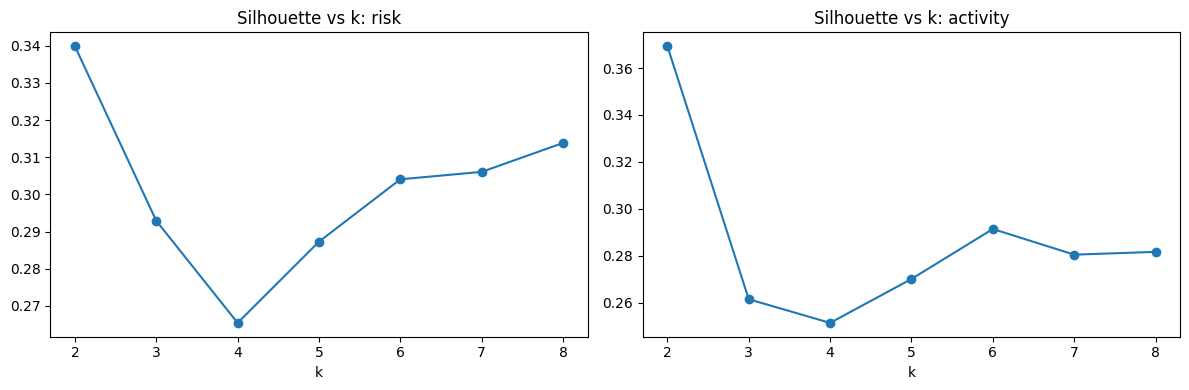

In [20]:
from sklearn.metrics import silhouette_score

rows = []
for nm, (X, raw) in mats.items():
    for k in range(2, 9):
        lab = AgglomerativeClustering(n_clusters=k, linkage="ward", metric="euclidean").fit_predict(X)
        sz = np.bincount(lab)
        rows.append(dict(matrix=nm, k=k, silhouette=silhouette_score(X, lab),
                         min_size=sz.min(), max_size=sz.max(), min_pct=100*sz.min()/len(X),
                         sizes=sz.tolist()))
cmp_df = pd.DataFrame(rows)
for nm in mats:
    print(f"\n=== {nm} ==="); print(cmp_df[cmp_df.matrix == nm].drop(columns="matrix").round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, nm in zip(ax, mats):
    d = cmp_df[cmp_df.matrix == nm]
    a.plot(d.k, d.silhouette, marker="o"); a.set_title(f"Silhouette vs k: {nm}"); a.set_xlabel("k")
plt.tight_layout(); plt.show()


=== risk ===
   silhouette       CH     DB  merge_gap  kmeans_inertia
k                                                       
2       0.340  182.948  1.058      3.012         625.010
3       0.293  224.138  1.087      7.180         464.071
4       0.265  210.187  0.964      0.737         373.954
5       0.287  216.262  0.987      0.552         311.854
6       0.304  237.084  0.911      3.264         267.455
7       0.306  236.370  0.844      0.035         228.707
8       0.314  246.332  0.858      2.365         196.031

=== activity ===
   silhouette       CH     DB  merge_gap  kmeans_inertia
k                                                       
2       0.369  166.344  1.150      5.694        1071.585
3       0.261  171.882  1.258      4.971         800.746
4       0.251  167.637  1.057      1.517         612.475
5       0.270  172.254  1.014      0.762         517.075
6       0.291  185.898  0.954      3.694         440.454
7       0.280  184.864  0.985      0.700         389.135

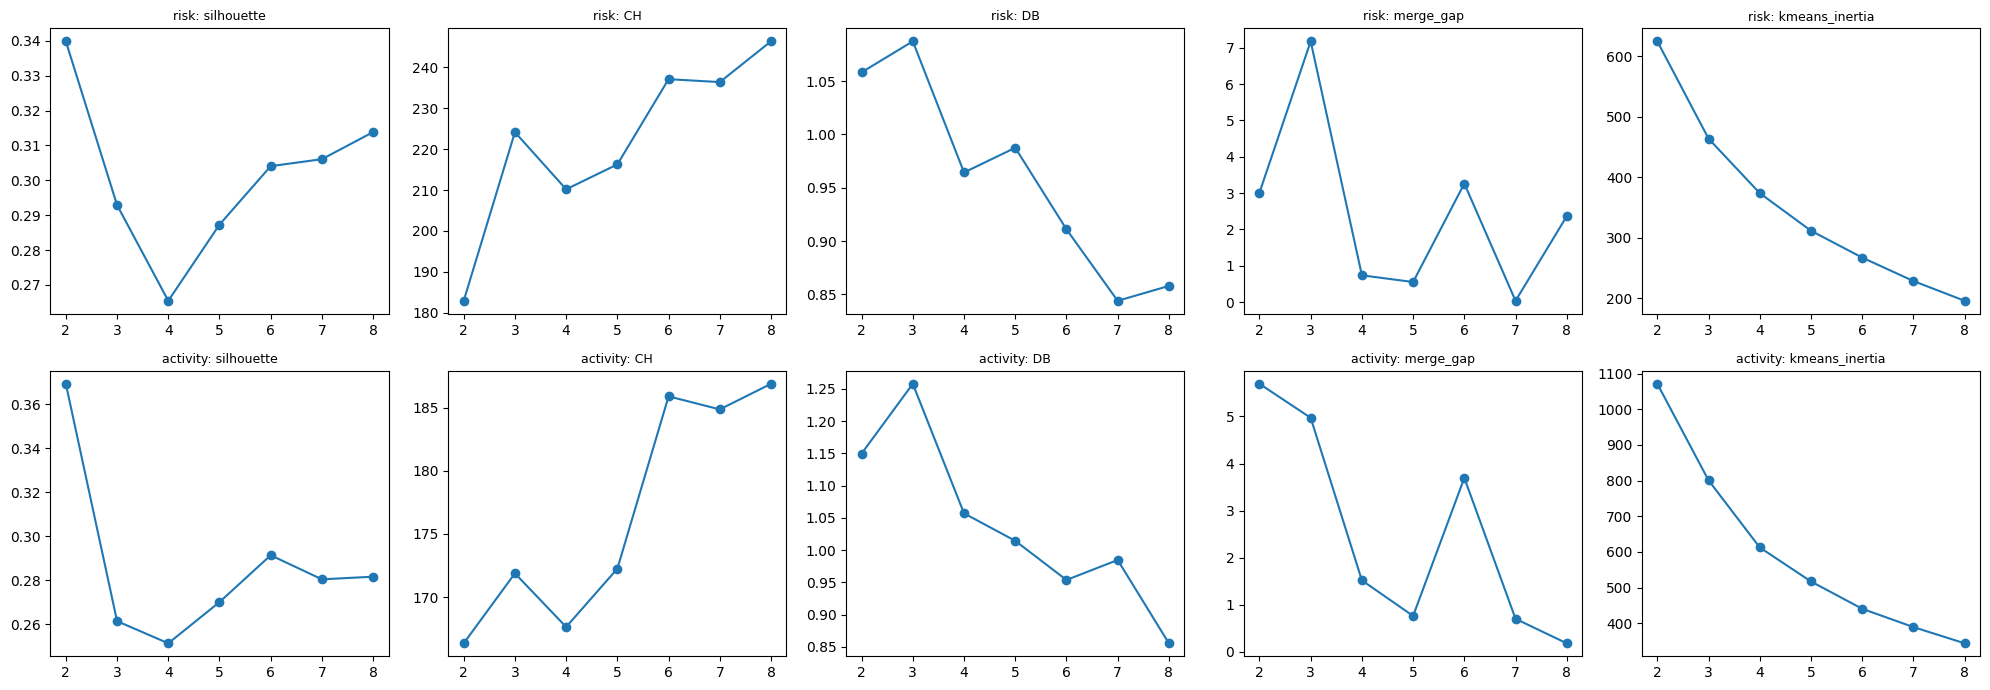

In [21]:
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)
K_RANGE = range(2, 9)
agg = lambda X, k: AgglomerativeClustering(n_clusters=k, linkage="ward", metric="euclidean").fit_predict(X)

def validity(nm):
    X = mats[nm][0].values
    h = Z[nm][:, 2]                                   # Ward merge heights
    rows = []
    for k in K_RANGE:
        lab = agg(X, k)
        rows.append(dict(k=k,
            silhouette=silhouette_score(X, lab),              # higher = better
            CH=calinski_harabasz_score(X, lab),               # higher = better
            DB=davies_bouldin_score(X, lab),                  # LOWER = better
            merge_gap=h[-(k-1)] - h[-k],                      # big gap = merging k->k-1 is costly
            kmeans_inertia=KMeans(k, n_init=20, random_state=42).fit(X).inertia_))  # for the elbow
    return pd.DataFrame(rows).set_index("k")

val = {nm: validity(nm) for nm in mats}
for nm in mats: print(f"\n=== {nm} ==="); print(val[nm].round(3))

fig, ax = plt.subplots(2, 5, figsize=(20, 7))
for i, nm in enumerate(mats):
    for j, c in enumerate(["silhouette", "CH", "DB", "merge_gap", "kmeans_inertia"]):
        ax[i, j].plot(val[nm].index, val[nm][c], marker="o"); ax[i, j].set_title(f"{nm}: {c}", fontsize=9)
plt.tight_layout(); plt.show()


=== Dunn index: risk (higher = better separated, tighter clusters) ===
   ward_classic  ward_centroid  ward_min_size  kmeans_classic  kmeans_centroid  kmeans_min_size
k                                                                                              
2         0.016          0.940             92           0.009            0.836              143
3         0.013          0.719             92           0.006            0.670              119
4         0.011          0.632             92           0.004            0.577               41
5         0.011          0.591             48           0.010            0.537               28
6         0.016          0.333              5           0.008            0.441               20
7         0.016          0.329              5           0.010            0.307                5
8         0.016          0.320              5           0.006            0.319                5
Best k, classic:  Ward = 2 | K-means = 5
Best k, centroid: Ward 

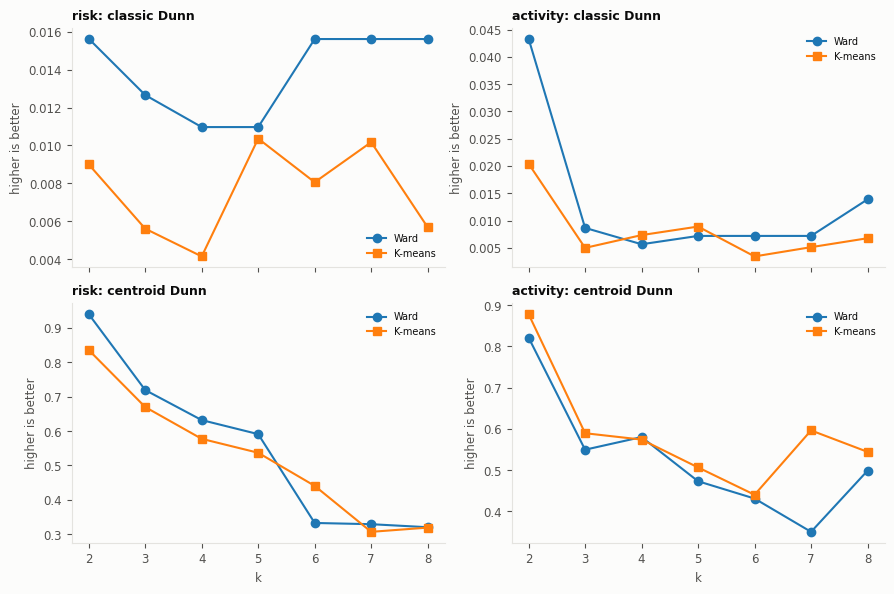

In [30]:
# ===== Dunn index, k = 2..8, Ward and K-means =====
#  (K-means table), next to the BIC / stability / prediction-strength cell
# Needs: mats (cell 16), K_RANGE and SEED (cell 21). Runs in a few seconds.
#
# Dunn index = (smallest distance between two different clusters) / (largest spread inside any cluster). Higher = better.
#  - Classic version: separation = closest pair of shares in different clusters; spread = the widest pair inside one cluster.
#    One outlier or one pair of touching shares changes it a lot, so it is often tiny (< 0.1) on continuous data.
#  - Centroid version (more robust): separation = closest pair of cluster centres;
#    spread = 2 x the largest average distance from a share to its own cluster centre.
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import KMeans, AgglomerativeClustering

n_init = N_INIT if "N_INIT" in globals() else 50
ward = lambda X, k: AgglomerativeClustering(n_clusters=k, linkage="ward", metric="euclidean").fit_predict(X)
kmeans = lambda X, k: KMeans(n_clusters=k, n_init=n_init, random_state=SEED).fit_predict(X)

def dunn(X, D, lab):
    ks = np.unique(lab)
    same = lab[:, None] == lab[None, :]
    classic = D[~same].min() / D[same].max()                                   # closest cross-cluster pair / widest within-cluster pair
    cen = np.vstack([X[lab == c].mean(axis=0) for c in ks])
    cd = squareform(pdist(cen))[np.triu_indices(len(ks), 1)]                    # distances between cluster centres
    spread = max(2 * np.linalg.norm(X[lab == c] - cen[i], axis=1).mean() for i, c in enumerate(ks))
    return classic, cd.min() / spread

dn = {}
for nm in mats:
    X = mats[nm][0].values; D = squareform(pdist(X)); rows = []
    for k in K_RANGE:
        row = dict(k=k)
        for algo, f in (("ward", ward), ("kmeans", kmeans)):
            lab = f(X, k); c, cen = dunn(X, D, lab)
            row[f"{algo}_classic"], row[f"{algo}_centroid"], row[f"{algo}_min_size"] = c, cen, int(np.bincount(lab).min())
        rows.append(row)
    dn[nm] = pd.DataFrame(rows).set_index("k")
    d = dn[nm]
    print(f"\n=== Dunn index: {nm} (higher = better separated, tighter clusters) ===")
    print(d.round(3).to_string())
    print(f"Best k, classic:  Ward = {d.ward_classic.idxmax()} | K-means = {d.kmeans_classic.idxmax()}")
    print(f"Best k, centroid: Ward = {d.ward_centroid.idxmax()} | K-means = {d.kmeans_centroid.idxmax()}")
    d.to_csv(f"data/dunn_index_{nm}.csv")

fig, ax = plt.subplots(2, len(mats), figsize=(9, 6), sharex=True)
for j, nm in enumerate(mats):
    for i, (kind, ttl) in enumerate([("classic", "classic Dunn"), ("centroid", "centroid Dunn")]):
        a = ax[i, j]; d = dn[nm]
        a.plot(d.index, d[f"ward_{kind}"], marker="o", label="Ward"); a.plot(d.index, d[f"kmeans_{kind}"], marker="s", label="K-means")
        a.set_title(f"{nm}: {ttl}", fontsize=9); a.set_ylabel("higher is better")
        if i == 1: a.set_xlabel("k")
        a.legend(fontsize=7, frameon=False)
plt.tight_layout(); plt.savefig("figures/dunn_index.png", dpi=200, bbox_inches="tight"); plt.show()

# How to read it:
# - Pick the k with the highest Dunn value, but expect small numbers: classic Dunn is often below 0.1 on continuous data.
# - Classic Dunn is driven by single extreme shares (for example a very high-beta share), so a jump at large k usually
#   means a tiny cluster has split off, not a better solution. Check min_size: a value of 1 or 2 is a warning sign.
# - Report it as one vote among your criteria, not as the deciding one.


=== Gaussian mixture information criteria: risk (lower = better) ===
   BIC_full  AIC_full  BIC_spherical  min_size_full  converged
k                                                             
2    2692.5    2646.4         2684.4             83       True
3    2721.3    2650.0         2701.7             72       True
4    2720.6    2624.2         2713.7             25       True
5    2737.9    2616.4         2716.9              4       True
6    2767.3    2620.6         2712.2              4       True
7    2776.8    2605.0         2733.5              1       True
8    2809.3    2612.3         2746.5              1       True
Lowest BIC (full covariance): k = 2 | lowest AIC: k = 7 | lowest BIC (spherical, closest to K-means): k = 2
BIC(k=2) - BIC(best) = 0.0

=== Gaussian mixture information criteria: activity (lower = better) ===
   BIC_full  AIC_full  BIC_spherical  min_size_full  converged
k                                                             
2    -433.7    -513.3       

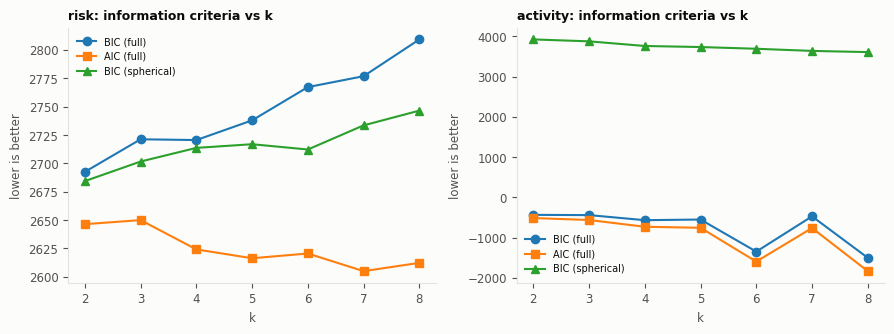

In [28]:
# ===== k selection with information criteria (Gaussian mixtures: BIC and AIC) =====
#  (where K_RISK / K_ACT are set).
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture

ic = {}
for nm in mats:
    X = mats[nm][0].values
    rows = []
    for k in K_RANGE:
        full = GaussianMixture(n_components=k, covariance_type="full", n_init=10, random_state=SEED).fit(X)
        sph = GaussianMixture(n_components=k, covariance_type="spherical", n_init=10, random_state=SEED).fit(X)
        rows.append(dict(k=k, BIC_full=full.bic(X), AIC_full=full.aic(X), BIC_spherical=sph.bic(X),
                         min_size_full=int(np.bincount(full.predict(X), minlength=k).min()),
                         converged=bool(full.converged_ and sph.converged_)))
    ic[nm] = pd.DataFrame(rows).set_index("k")
    d = ic[nm]
    print(f"\n=== Gaussian mixture information criteria: {nm} (lower = better) ===")
    print(d.round(1).to_string())
    print(f"Lowest BIC (full covariance): k = {d.BIC_full.idxmin()} | lowest AIC: k = {d.AIC_full.idxmin()} "
          f"| lowest BIC (spherical, closest to K-means): k = {d.BIC_spherical.idxmin()}")
    # how strong is the preference for the winner over k=2?  (difference > 10 = strong evidence)
    print(f"BIC(k=2) - BIC(best) = {d.BIC_full[2] - d.BIC_full.min():.1f}")
    d.to_csv(f"data/gmm_information_criteria_{nm}.csv")

fig, ax = plt.subplots(1, len(mats), figsize=(9, 3.4))
for a, nm in zip(np.atleast_1d(ax), mats):
    d = ic[nm]
    a.plot(d.index, d.BIC_full, marker="o", label="BIC (full)")
    a.plot(d.index, d.AIC_full, marker="s", label="AIC (full)")
    a.plot(d.index, d.BIC_spherical, marker="^", label="BIC (spherical)")
    a.set_title(f"{nm}: information criteria vs k", fontsize=9); a.set_xlabel("k"); a.set_ylabel("lower is better")
    a.legend(fontsize=7, frameon=False)
plt.tight_layout(); plt.savefig("figures/gmm_information_criteria.png", dpi=200, bbox_inches="tight"); plt.show()

# How to read it:
# - Pick the k with the lowest BIC; report AIC beside it.
# - If BIC keeps falling all the way to k=8, there is no clear minimum. That usually means the features are not
#   Gaussian (Recency is skewed, Frequency is a small count), not that 8 groups exist. Say so in the report.


=== Resample stability: risk (50 subsets of 390 of 488 shares; ARI vs full-sample clusters) ===
   ward_mean  ward_min  ward_sd  kmeans_mean  kmeans_min  kmeans_sd
k                                                                  
2      0.405    -0.080    0.242        0.962       0.712      0.063
3      0.380     0.102    0.143        0.951       0.815      0.046
4      0.373     0.169    0.116        0.814       0.314      0.137
5      0.442     0.291    0.104        0.774       0.290      0.150
6      0.488     0.297    0.117        0.562       0.323      0.167
7      0.515     0.296    0.122        0.567       0.397      0.150
8      0.526     0.333    0.122        0.752       0.423      0.136
Most stable k: Ward = 8 (mean ARI 0.526) | K-means = 2 (mean ARI 0.962)

=== Resample stability: activity (50 subsets of 390 of 488 shares; ARI vs full-sample clusters) ===
   ward_mean  ward_min  ward_sd  kmeans_mean  kmeans_min  kmeans_sd
k                                                 

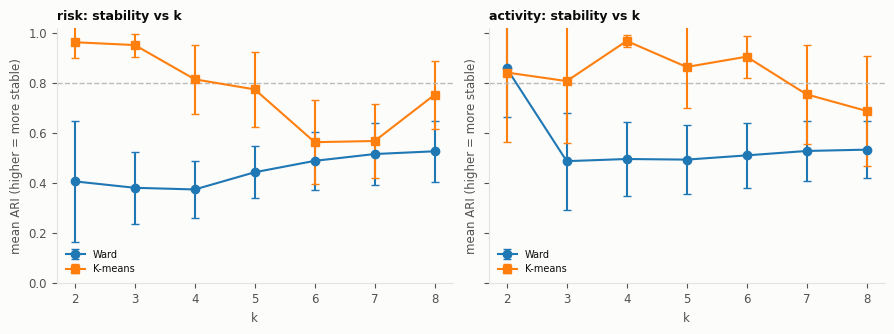

In [29]:
# ===== Resample stability of the clusters (Ward and K-means), k = 2..8 ===== (where K_RISK / K_ACT are set).
# Needs: mats (cell 16), K_RANGE and SEED (cell 21). Takes roughly 1-2 minutes.
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

N_RESAMPLES, FRAC = 50, 0.80                      # 50 random subsets, each keeping 80% of the shares
rng = np.random.default_rng(SEED)
ward = lambda X, k: AgglomerativeClustering(n_clusters=k, linkage="ward", metric="euclidean").fit_predict(X)
kmeans = lambda X, k, n_init: KMeans(n_clusters=k, n_init=n_init, random_state=SEED).fit_predict(X)

stab = {}
for nm in mats:
    X = mats[nm][0].values; n = len(X); m = int(round(FRAC * n))
    subsets = [np.sort(rng.choice(n, size=m, replace=False)) for _ in range(N_RESAMPLES)]   # same subsets for every k and method
    rows = []
    for k in K_RANGE:
        ref = {"ward": ward(X, k), "kmeans": kmeans(X, k, 50)}                               # reference = full-sample solution
        row = dict(k=k)
        for algo in ("ward", "kmeans"):
            aris = []
            for idx in subsets:
                lab = ward(X[idx], k) if algo == "ward" else kmeans(X[idx], k, 10)
                aris.append(adjusted_rand_score(ref[algo][idx], lab))                        # compare on the shares both runs contain
            row[f"{algo}_mean"], row[f"{algo}_min"], row[f"{algo}_sd"] = np.mean(aris), np.min(aris), np.std(aris)
        rows.append(row)
    stab[nm] = pd.DataFrame(rows).set_index("k")
    d = stab[nm]
    print(f"\n=== Resample stability: {nm} ({N_RESAMPLES} subsets of {m} of {n} shares; ARI vs full-sample clusters) ===")
    print(d.round(3).to_string())
    print(f"Most stable k: Ward = {d.ward_mean.idxmax()} (mean ARI {d.ward_mean.max():.3f}) | "
          f"K-means = {d.kmeans_mean.idxmax()} (mean ARI {d.kmeans_mean.max():.3f})")
    d.to_csv(f"data/resample_stability_{nm}.csv")

fig, ax = plt.subplots(1, len(mats), figsize=(9, 3.4), sharey=True)
for a, nm in zip(np.atleast_1d(ax), mats):
    d = stab[nm]
    a.errorbar(d.index, d.ward_mean, yerr=d.ward_sd, marker="o", capsize=3, label="Ward")
    a.errorbar(d.index, d.kmeans_mean, yerr=d.kmeans_sd, marker="s", capsize=3, label="K-means")
    a.axhline(0.8, color="#bbbbbb", lw=1, ls="--"); a.set_ylim(0, 1.02)
    a.set_title(f"{nm}: stability vs k", fontsize=9); a.set_xlabel("k"); a.set_ylabel("mean ARI (higher = more stable)")
    a.legend(fontsize=7, frameon=False)
plt.tight_layout(); plt.savefig("figures/resample_stability.png", dpi=200, bbox_inches="tight"); plt.show()

# How to read it:
# - Mean ARI near 1 = the same shares end up together whichever 80% you cluster. The dashed line (0.8) is a common rule of thumb.
# - Small k is usually the most stable, so look at where the curve DROPS, not only at the highest point.
# - Report: "mean ARI over 50 subsamples = X for k=..., so the groups are (not) reproducible".


=== DBSCAN: risk (488 shares, 2 features) ===
At the knee of each k-distance curve:
  eps  min_samples  clusters  noise_pct top_sizes  second_size  silhouette
0.421            3         2        4.5  [463, 3]            3       0.495
0.425            4         2        4.3  [463, 4]            4       0.508
0.652           10         1        3.7     [470]            0         NaN

How many clusters does DBSCAN find across the whole grid (75 settings)?
clusters found
1     23
2      9
3      4
5      3
6      2
7      1
8      1
9      6
10     1
11     1
12     1
13     3
14     2
15     2
16     2
17     2
18     2
21     1
23     1
24     2
25     1
26     1
27     2
30     2
No setting gives two substantial clusters (second one at least 5% of shares) with at most 20% noise: no clear density gap in this matrix.

Noise shares at min_samples=4, eps at the knee (21): ALB, ALGN, BAX, BF-B, CVNA, DG, EL, GNRC, LLY, MRVL, NVDA, OKTA, PLTR, SMCI, TPL, TRGP, TSLA, TWLO, VRT, VST, XYZ

=== 

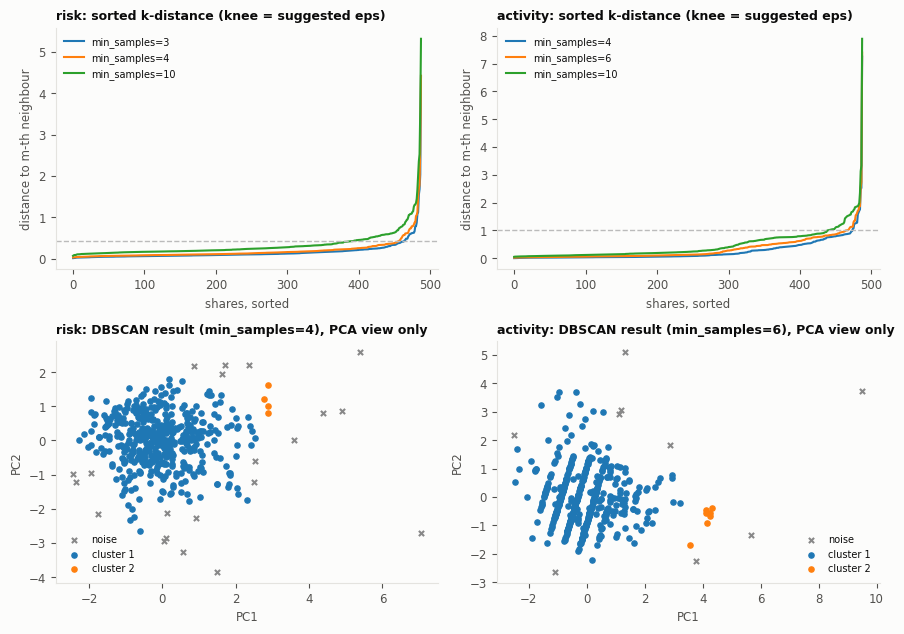

In [31]:
# ===== DBSCAN density test (no k needed) =====
# Paste AFTER cell 21 with the other k-selection cells and BEFORE cell 22. Needs only: mats (cell 16). Runs in seconds.
#
# DBSCAN calls a share a "core" share if at least MIN_SAMPLES shares (itself included) lie within distance EPS.
# Clusters are chains of core shares; shares that belong to no dense region are labelled NOISE (label -1).
# It chooses the number of clusters itself, so it is an independent check on k, and it flags outlier shares.
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

def knee(y):
    """Point of the sorted k-distance curve that is furthest from the straight line joining its ends (the 'elbow')."""
    x = np.arange(len(y)); x0, y0, x1, y1 = 0, y[0], len(y) - 1, y[-1]
    return y[np.argmax(np.abs((y1 - y0) * x - (x1 - x0) * y + x1 * y0 - y1 * x0) / np.hypot(y1 - y0, x1 - x0))]

def run(X, eps, ms):
    lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
    keep = lab != -1; ncl = len(set(lab[keep]))
    sil = silhouette_score(X[keep], lab[keep]) if ncl >= 2 and keep.sum() > ncl else np.nan
    sizes = sorted(np.bincount(lab[keep]).tolist(), reverse=True)[:4] if keep.any() else []
    second = sizes[1] if len(sizes) > 1 else 0                    # size of the 2nd-largest cluster
    return lab, dict(eps=round(float(eps), 3), min_samples=ms, clusters=ncl, noise_pct=round(100 * (~keep).mean(), 1), top_sizes=sizes,
                     second_size=second, silhouette=sil)

out = {}
for nm in mats:
    Xdf = mats[nm][0]; X = Xdf.values; d = X.shape[1]
    ms_list = sorted({d + 1, 2 * d, 10})                          # usual rules of thumb: d+1, 2d, and a larger value
    curves = {ms: np.sort(NearestNeighbors(n_neighbors=ms).fit(X).kneighbors(X)[0][:, -1]) for ms in ms_list}

    # (a) one DBSCAN at the knee of each k-distance curve
    rows, labs = [], {}
    for ms in ms_list:
        lab, info = run(X, knee(curves[ms]), ms); rows.append(info); labs[ms] = lab
    knee_tab = pd.DataFrame(rows)
    print(f"\n=== DBSCAN: {nm} ({len(X)} shares, {d} features) ===\nAt the knee of each k-distance curve:\n{knee_tab.round(3).to_string(index=False)}")

    # (b) grid over eps (50th to 99th percentile of the k-distances) x min_samples
    grid = []
    for ms in ms_list:
        for eps in np.unique(np.quantile(curves[ms], np.linspace(0.50, 0.99, 25))):
            grid.append(run(X, eps, ms)[1])
    g = pd.DataFrame(grid)
    print("\nHow many clusters does DBSCAN find across the whole grid (%d settings)?" % len(g))
    print(g.clusters.value_counts().sort_index().rename("number of settings").rename_axis("clusters found").to_string())
    ok = g[(g.clusters >= 2) & (g.noise_pct <= 20) & (g.second_size >= 0.05 * len(X))].dropna(subset=["silhouette"])   # two SUBSTANTIAL clusters
    if len(ok):
        print("Best setting with 2+ clusters, the 2nd one holding at least 5% of shares, and at most 20% noise (by silhouette):\n", ok.sort_values("silhouette", ascending=False).head(3).round(3).to_string(index=False))
    else:
        print("No setting gives two substantial clusters (second one at least 5% of shares) with at most 20% noise: no clear density gap in this matrix.")
    g.to_csv(f"data/dbscan_grid_{nm}.csv", index=False)

    # (c) outliers (noise) at the 2d rule-of-thumb setting
    ms_pick = 2 * d; lab = labs[ms_pick]; noise = Xdf.index[lab == -1]
    print(f"\nNoise shares at min_samples={ms_pick}, eps at the knee ({len(noise)}): {', '.join(map(str, noise[:30]))}{' ...' if len(noise) > 30 else ''}")
    out[nm] = dict(curves=curves, labs=lab, ms=ms_pick, X=X, eps=knee(curves[ms_pick]))

fig, ax = plt.subplots(2, len(mats), figsize=(9, 6.4))
for j, nm in enumerate(mats):
    o = out[nm]; a = ax[0, j]
    for ms, c in o["curves"].items(): a.plot(c, label=f"min_samples={ms}")
    a.axhline(o["eps"], color="#bbbbbb", ls="--", lw=1)
    a.set_title(f"{nm}: sorted k-distance (knee = suggested eps)", fontsize=9); a.set_xlabel("shares, sorted"); a.set_ylabel("distance to m-th neighbour")
    a.legend(fontsize=7, frameon=False)
    a = ax[1, j]; P = PCA(n_components=2, random_state=0).fit_transform(o["X"]); lab = o["labs"]
    a.scatter(P[lab == -1, 0], P[lab == -1, 1], s=14, color="#888888", marker="x", label="noise")
    for i, c in enumerate(sorted(set(lab) - {-1})):
        a.scatter(P[lab == c, 0], P[lab == c, 1], s=14, label=f"cluster {c + 1}")
    a.set_title(f"{nm}: DBSCAN result (min_samples={o['ms']}), PCA view only", fontsize=9); a.set_xlabel("PC1"); a.set_ylabel("PC2")
    a.legend(fontsize=7, frameon=False)
plt.tight_layout(); plt.savefig("figures/dbscan.png", dpi=200, bbox_inches="tight"); plt.show()

# How to read it:
# - One big cluster plus a little noise at sensible settings = the shares form one continuous cloud with no gap between dense
#   groups, so the structure is weak. That agrees with moderate silhouette scores and is a finding in itself.
# - 2 or more clusters with little noise would be independent support for that k.
# - Many tiny clusters or more than 30% noise means eps is too small for the data, not that the data has many groups.
# - Noise shares are the outliers (very high beta, very high Monetary...). Name a few of them in the report.
# - DBSCAN assumes similar density everywhere, and results move a lot with eps, so treat it as one check, not the decider.

In [22]:
def Wk(X, lab):
    return sum(((X[lab == c] - X[lab == c].mean(0))**2).sum() for c in np.unique(lab))

def gap_stat(nm, B=20, seed=0):
    rng = np.random.default_rng(seed); X = mats[nm][0].values
    mn, mx = X.min(0), X.max(0); out = []
    for k in K_RANGE:
        w = np.log(Wk(X, agg(X, k)))
        wb = [np.log(Wk(R, agg(R, k))) for R in (rng.uniform(mn, mx, X.shape) for _ in range(B))]
        out.append(dict(k=k, gap=np.mean(wb) - w, s=np.std(wb) * np.sqrt(1 + 1/B)))
    g = pd.DataFrame(out).set_index("k")
    # Tibshirani rule: smallest k with gap(k) >= gap(k+1) - s(k+1)
    g["rule_met"] = [g.gap[k] >= g.gap[k+1] - g.s[k+1] if k < 8 else np.nan for k in g.index]
    return g

gaps = {nm: gap_stat(nm) for nm in mats}
for nm in mats:
    print(f"\n=== gap statistic: {nm} ==="); print(gaps[nm].round(3))
    print("Tibshirani choice:", next((k for k in gaps[nm].index if gaps[nm].rule_met[k] is True), "none met"))


=== gap statistic: risk ===
     gap      s rule_met
k                       
2  1.716  0.047     True
3  1.655  0.069     True
4  1.449  0.068     True
5  1.432  0.040     True
6  1.465  0.051     True
7  1.424  0.056     True
8  1.425  0.047      NaN
Tibshirani choice: none met

=== gap statistic: activity ===
     gap      s rule_met
k                       
2  1.571  0.042    False
3  1.607  0.032     True
4  1.590  0.034     True
5  1.613  0.038    False
6  1.675  0.035     True
7  1.692  0.038     True
8  1.717  0.036      NaN
Tibshirani choice: none met


In [23]:
def Wk(X, lab):
    return sum(((X[lab == c] - X[lab == c].mean(0))**2).sum() for c in np.unique(lab))

def gap_stat(nm, B=20, seed=0):
    rng = np.random.default_rng(seed); X = mats[nm][0].values
    mn, mx = X.min(0), X.max(0); out = []
    for k in K_RANGE:
        w = np.log(Wk(X, agg(X, k)))
        wb = [np.log(Wk(R, agg(R, k))) for R in (rng.uniform(mn, mx, X.shape) for _ in range(B))]
        out.append(dict(k=k, gap=np.mean(wb) - w, s=np.std(wb) * np.sqrt(1 + 1/B)))
    g = pd.DataFrame(out).set_index("k")
    # Tibshirani rule: smallest k with gap(k) >= gap(k+1) - s(k+1)
    g["rule_met"] = [g.gap[k] >= g.gap[k+1] - g.s[k+1] if k < 8 else np.nan for k in g.index]
    return g

gaps = {nm: gap_stat(nm) for nm in mats}
for nm in mats:
    print(f"\n=== gap statistic: {nm} ==="); print(gaps[nm].round(3))
    print("Tibshirani choice:", next((k for k in gaps[nm].index if gaps[nm].rule_met[k] is True), "none met"))


=== gap statistic: risk ===
     gap      s rule_met
k                       
2  1.716  0.047     True
3  1.655  0.069     True
4  1.449  0.068     True
5  1.432  0.040     True
6  1.465  0.051     True
7  1.424  0.056     True
8  1.425  0.047      NaN
Tibshirani choice: none met

=== gap statistic: activity ===
     gap      s rule_met
k                       
2  1.571  0.042    False
3  1.607  0.032     True
4  1.590  0.034     True
5  1.613  0.038    False
6  1.675  0.035     True
7  1.692  0.038     True
8  1.717  0.036      NaN
Tibshirani choice: none met



=== K-means: risk ===
   inertia  silhouette       CH     DB  min_size  max_size  min_pct                             sizes  inertia_spread_1init  inertia_drop_pct
k                                                                                                                                            
2  625.010       0.387  272.925  1.071       143       345   29.303                        [345, 143]                 0.030               NaN
3  464.071       0.328  267.508  1.012       119       203   24.385                   [203, 166, 119]                 0.018            25.750
4  373.928       0.325  259.767  0.939        41       167    8.402               [167, 150, 130, 41]                25.356            19.424
5  311.854       0.339  257.157  0.871        28       164    5.738           [164, 127, 114, 28, 55]                19.709            16.601
6  266.927       0.328  256.080  0.886        20       137    4.098        [56, 20, 137, 77, 115, 83]                38.308  

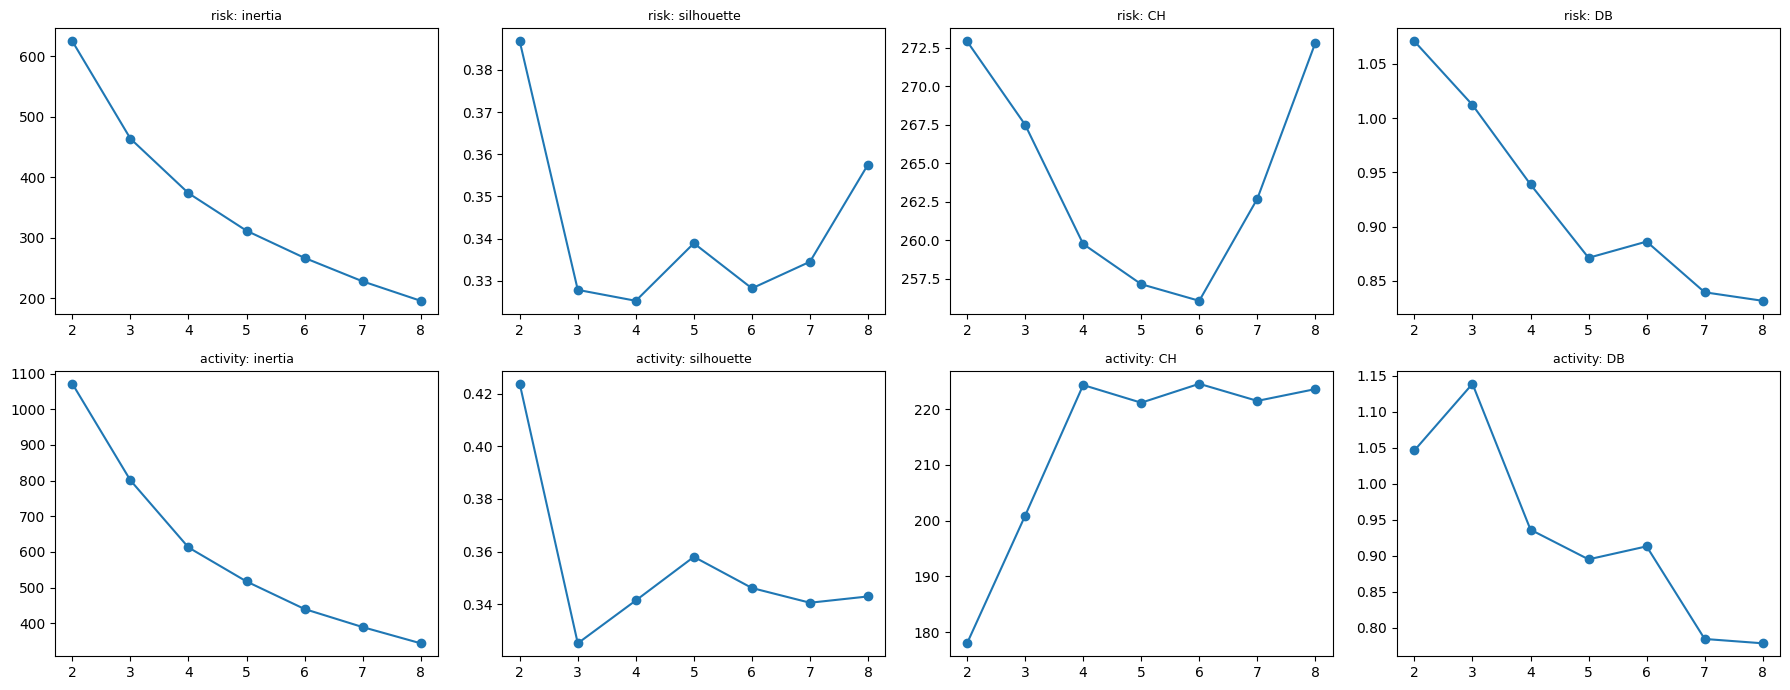

In [24]:
 from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)

SEED, N_INIT, K_RANGE = 42, 50, range(2, 9)       # fixed seed; best of 50 starts kept per k

def kmeans_table(nm):
    X = mats[nm][0].values
    rows = []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X)
        sz = np.bincount(km.labels_)
        single = [KMeans(k, n_init=1, random_state=s).fit(X).inertia_ for s in range(20)]
        rows.append(dict(k=k, inertia=km.inertia_,
                         silhouette=silhouette_score(X, km.labels_),
                         CH=calinski_harabasz_score(X, km.labels_),
                         DB=davies_bouldin_score(X, km.labels_),
                         min_size=sz.min(), max_size=sz.max(), min_pct=100*sz.min()/len(X),
                         sizes=sz.tolist(),
                         inertia_spread_1init=max(single) - min(single)))   # shows why n_init matters
    d = pd.DataFrame(rows).set_index("k")
    d["inertia_drop_pct"] = -d["inertia"].pct_change() * 100                 # elbow: gain from adding a cluster
    return d

km_val = {nm: kmeans_table(nm) for nm in mats}
for nm in mats:
    print(f"\n=== K-means: {nm} ==="); print(km_val[nm].round(3).to_string())
    km_val[nm].to_csv(f"data/kmeans_validity_{nm}.csv")

fig, ax = plt.subplots(2, 4, figsize=(18, 7))
for i, nm in enumerate(mats):
    for j, c in enumerate(["inertia", "silhouette", "CH", "DB"]):
        ax[i, j].plot(km_val[nm].index, km_val[nm][c], marker="o"); ax[i, j].set_title(f"{nm}: {c}", fontsize=9)
plt.tight_layout(); plt.show()


=== risk | agglom (original units) ===
     n   pct  mean_weekly_return_median  weekly_beta_median  mean_weekly_return_mean  weekly_beta_mean
0  396  81.1                     0.0021              0.8850                   0.0021            0.8985
1   92  18.9                     0.0055              1.2177                   0.0063            1.2981

=== risk | kmeans (original units) ===
     n   pct  mean_weekly_return_median  weekly_beta_median  mean_weekly_return_mean  weekly_beta_mean
0  345  70.7                     0.0019              0.8407                   0.0018            0.8178
1  143  29.3                     0.0049              1.2781                   0.0053            1.3505

=== activity | agglom (original units) ===
     n   pct  R_recency_days_median  F_frequency_median  M_usd_median  R_recency_days_mean  F_frequency_mean    M_usd_mean
0  402  82.4                   11.0                 3.0  1.539575e+10              12.5572            3.2040  3.738926e+10
1   86  17.6

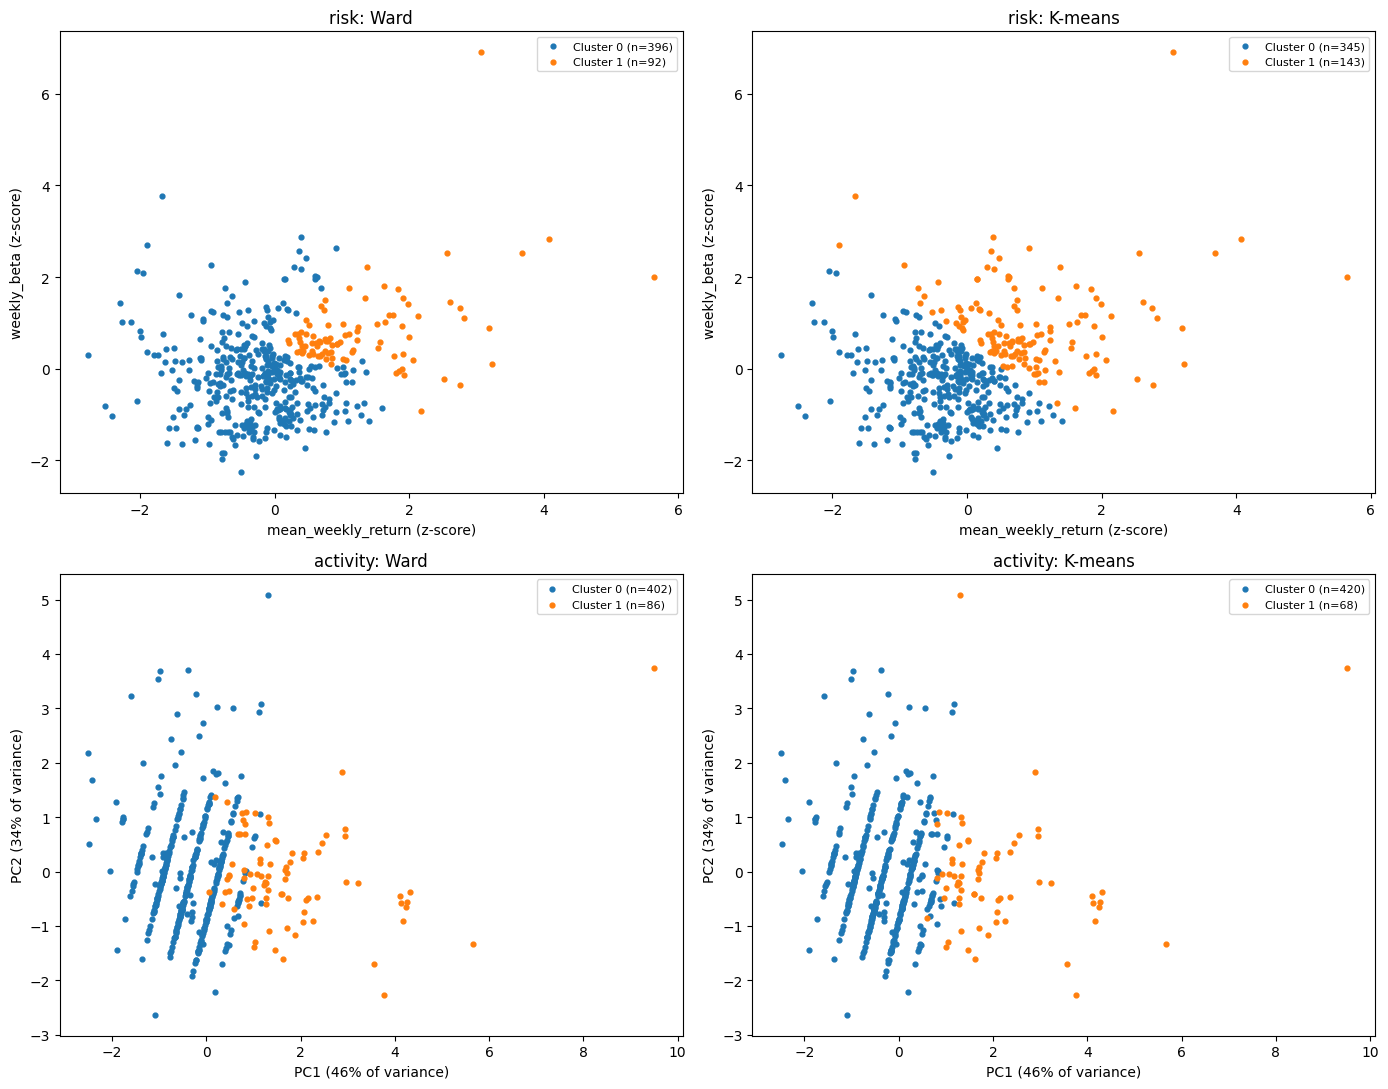

In [25]:
from scipy.optimize import linear_sum_assignment
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# Define the chosen number of clusters for each combination
# (Based on your previous validation, k=2 often gave the best silhouette metrics)
K_RISK = 2       # Ward / Agglomerative clustering for Risk features
K_RISK_KM = 2    # K-Means clustering for Risk features
K_ACT = 2        # Ward / Agglomerative clustering for Activity features
K_ACT_KM = 2     # K-Means clustering for Activity features

sel = {"risk": (K_RISK, K_RISK_KM), "activity": (K_ACT, K_ACT_KM)}
labs = {}
for nm, (ka, kk) in sel.items():
    X = mats[nm][0]
    labs[nm] = {"agglom": pd.Series(agg(X.values, ka), index=X.index),
                "kmeans": pd.Series(KMeans(kk, n_init=N_INIT, random_state=SEED).fit_predict(X.values), index=X.index)}

# ---- Profiles in ORIGINAL units (medians robust to outliers; means shown for comparison) ----
def profile_table(nm, algo):
    raw, lab = mats[nm][1], labs[nm][algo]
    g = raw.groupby(lab)
    p = g.median().add_suffix("_median").join(g.mean().add_suffix("_mean"))
    p.insert(0, "n", lab.value_counts().sort_index()); p.insert(1, "pct", (100*p["n"]/len(lab)).round(1))
    return p
for nm in mats:
    for algo in ("agglom", "kmeans"):
        print(f"\n=== {nm} | {algo} (original units) ==="); print(profile_table(nm, algo).round(4).to_string())

# ---- Compare the two algorithms on the same shares ----
def align(a, b):                                   # match K-means labels to Ward labels (numbering is arbitrary)
    ct = pd.crosstab(a, b); r, c = linear_sum_assignment(-ct.values)
    return ct, dict(zip(ct.columns[c], ct.index[r]))
agree = {}
for nm in mats:
    X = mats[nm][0]; a, b = labs[nm]["agglom"], labs[nm]["kmeans"]
    ct, mp = align(a, b)
    agree[nm] = dict(ARI=adjusted_rand_score(a, b), matched_pct=100*(a == b.map(mp)).mean(),
                     sil_ward=silhouette_score(X, a), sil_kmeans=silhouette_score(X, b))
    print(f"\n{nm}: crosstab (rows Ward, cols K-means)"); print(ct)
print(pd.DataFrame(agree).T.round(3))

# ---- Labelled 2-D visualisation ----
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for i, nm in enumerate(mats):
    X = mats[nm][0]
    if X.shape[1] == 2:                            # risk: already 2-D, no reduction needed
        P = X.values; xl, yl = [f"{c} (z-score)" for c in X.columns]
    else:                                          # activity: 3 features -> PCA to 2-D
        pca = PCA(2, random_state=SEED).fit(X.values); P = pca.transform(X.values); ev = pca.explained_variance_ratio_
        print(f"\n{nm}: PCA variance explained {ev.round(3)}, total {ev.sum():.3f}")
        print(pd.DataFrame(pca.components_.T, index=X.columns, columns=["PC1", "PC2"]).round(3))
        xl, yl = f"PC1 ({ev[0]:.0%} of variance)", f"PC2 ({ev[1]:.0%} of variance)"
    for j, algo in enumerate(("agglom", "kmeans")):
        ax = axes[i, j]; lab = labs[nm][algo].values
        for c in np.unique(lab):
            ax.scatter(P[lab == c, 0], P[lab == c, 1], s=12, label=f"Cluster {c} (n={np.sum(lab == c)})")
        ax.set_xlabel(xl); ax.set_ylabel(yl); ax.set_title(f"{nm}: {'Ward' if algo == 'agglom' else 'K-means'}"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [26]:
# ---------- Inputs: R, F, log1p(M) for the same shares as the selected Ward RFM solution ----------
A = act_df[["R_recency_days", "F_frequency"]].assign(logM=np.log1p(act_df["M_usd"]))
cols = list(A.columns)
assert A.index.equals(X_act.index), "Shares differ from the clustered activity matrix"

# ================= 2.5.1 Correlation analysis =================
print("Pearson:\n", A.corr().round(3))
print("\nSpearman:\n", A.corr(method="spearman").round(3))

Xs = pd.DataFrame(StandardScaler().fit_transform(A), index=A.index, columns=cols)
ev, vec = np.linalg.eigh(np.corrcoef(Xs.values.T)); o = np.argsort(ev)[::-1]
print("\nEigenvalues:", ev[o].round(3), "| share of variance:", (ev[o] / ev.sum()).round(3))
print(pd.DataFrame(vec[:, o], index=cols, columns=["PC1", "PC2", "PC3"]).round(3))

def eta2(df, lab):                      # share of each feature's variance explained by cluster membership
    out = {}
    for c in df.columns:
        gm = df[c].mean(); ssb = sum(len(g) * (g.mean() - gm) ** 2 for _, g in df[c].groupby(lab))
        out[c] = ssb / ((df[c] - gm) ** 2).sum()
    return pd.Series(out)

labF = pd.Series(agg(Xs.values, K_ACT), index=Xs.index)      # selected Ward RFM solution
print("\neta^2 per feature (Ward RFM clusters):\n", eta2(Xs, labF).round(3))

# ================= 2.5.2 Remove Monetary =================
XRF = pd.DataFrame(StandardScaler().fit_transform(A[["R_recency_days", "F_frequency"]]),
                   index=A.index, columns=["R", "F"])        # standardised afresh
labRF = pd.Series(agg(XRF.values, K_ACT), index=XRF.index)   # same shares, same k, same Ward settings

print("\nARI (full RFM vs R,F only):", round(adjusted_rand_score(labF, labRF), 3))
print(pd.crosstab(labF, labRF, rownames=["RFM"], colnames=["R,F only"]))

for name, lab in [("RFM (3 features)", labF), ("R,F only", labRF)]:
    t = act_df.groupby(lab).agg(n=("M_usd", "size"), R_median=("R_recency_days", "median"),
                                F_median=("F_frequency", "median"),
                                M_median_usd=("M_usd", "median"), M_mean_usd=("M_usd", "mean"))
    t["logM_median"] = A.groupby(lab)["logM"].median()
    print(f"\n--- {name}: traded-value profile ---"); print(t.round(2).to_string())

print("\neta^2 of logM: RFM clusters =", round(eta2(A[["logM"]], labF)["logM"], 3),
      "| R,F-only clusters =", round(eta2(A[["logM"]], labRF)["logM"], 3))

Pearson:
                 R_recency_days  F_frequency   logM
R_recency_days           1.000       -0.346  0.153
F_frequency             -0.346        1.000  0.013
logM                     0.153        0.013  1.000

Spearman:
                 R_recency_days  F_frequency   logM
R_recency_days           1.000       -0.198  0.138
F_frequency             -0.198        1.000 -0.048
logM                     0.138       -0.048  1.000

Eigenvalues: [1.374 1.009 0.617] | share of variance: [0.458 0.336 0.206]
                  PC1    PC2    PC3
R_recency_days  0.711  0.023  0.702
F_frequency    -0.650  0.403  0.645
logM            0.269  0.915 -0.302

eta^2 per feature (Ward RFM clusters):
 R_recency_days    0.633
F_frequency       0.124
logM              0.008
dtype: float64

ARI (full RFM vs R,F only): 0.923
R,F only    0   1
RFM              
0         396   6
1           2  84

--- RFM (3 features): traded-value profile ---
     n  R_median  F_median  M_median_usd    M_mean_usd  logM_median


agglom: K_RISK=2, K_ACT=2, shares=488

Risk/return clusters (original units, return in % per week)
       n  return_%_median  return_%_mean  beta_median  beta_mean
R1  396             0.21          0.205        0.885      0.899
R2   92             0.55          0.632        1.218      1.298

RFM clusters (original units, M in USD bn over 60 sessions)
       n  R_days_median  F_median  M_$bn_median  M_$bn_mean
A1  402           11.0       3.0         15.40       37.39
A2   86           54.0       2.0         21.45       48.25


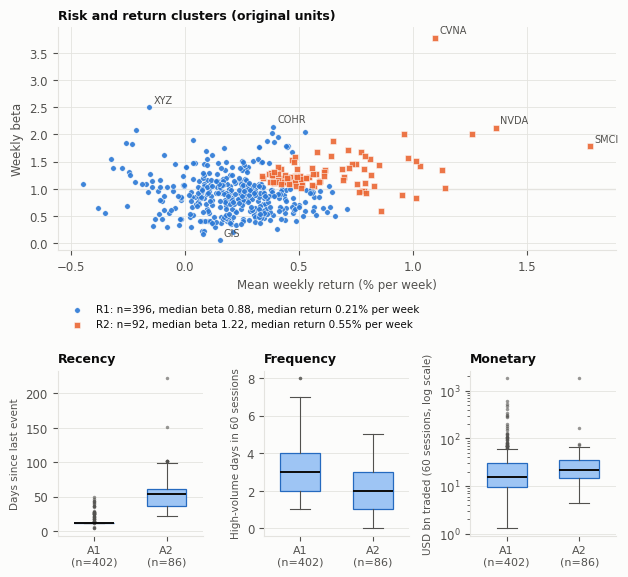


Sector mix, Risk and return clusters (% of each cluster; All = share of all shares)
 col_0                     R1    R2   All
GICS Sector                             
Industrials             14.6  22.8  16.2
Financials              15.4  14.1  15.2
Information Technology  11.4  31.5  15.2
Health Care             14.1   2.2  11.9
Consumer Discretionary   9.1  12.0   9.6
Consumer Staples         8.1   0.0   6.6
Utilities                7.3   1.1   6.1
Real Estate              6.8   3.3   6.1
Materials                5.3   3.3   4.9
Energy                   4.0   4.3   4.1
Communication Services   3.8   5.4   4.1
Most over-represented (lift, n>=5): [('Information Technology', 'R2', 2.08, 29), ('Industrials', 'R2', 1.41, 21), ('Communication Services', 'R2', 1.33, 5)]
Most under-represented (lift, n>=5): [('Information Technology', 'R1', 0.75, 45), ('Industrials', 'R1', 0.9, 58), ('Communication Services', 'R1', 0.92, 15)]

Sector mix, RFM clusters (% of each cluster; All = share of all s

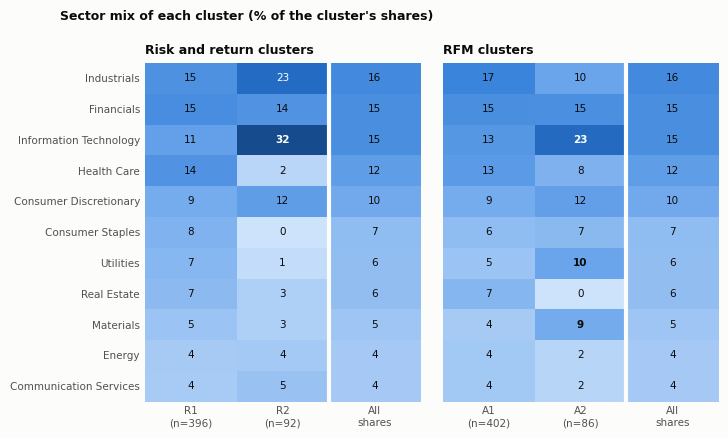

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
# ============ Task 3 pictures only: cluster profiles + sector composition ============
# Paste into ONE Colab cell AFTER cell 22 (the cell that sets K_RISK / K_ACT and builds `labs`).
# Needs only: sp500, risk_df, act_df, labs, K_RISK, K_ACT. No downloads, no tests, runs in a few seconds.
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

ALGO = "agglom"            # "agglom" = Ward (recommended for the report), or "kmeans"
os.makedirs("figures", exist_ok=True); os.makedirs("data", exist_ok=True)
need = ["sp500", "risk_df", "act_df", "labs", "K_RISK", "K_ACT"]
missing = [v for v in need if v not in globals()]
assert not missing, f"Run the earlier cells first - missing: {missing}"

# ---- style: one blue ramp, three category colours (marker shape is a second cue), text in dark grey ----
INK, INK2, SURF, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
CAT, MARK = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"], ["o", "s", "^", "D"]
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#6da7ec", "#2a78d6", "#184f95", "#0d366b"])
plt.rcParams.update({"font.size": 8.5, "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "text.color": INK, "axes.titlesize": 9, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "figure.facecolor": SURF, "axes.facecolor": SURF,
                     "axes.spines.top": False, "axes.spines.right": False, "savefig.facecolor": SURF})

# ---- labels: R1.. = lowest beta first; A1.. = most recently active first ----
def order_labels(lab, key, prefix):
    med = key.groupby(lab).mean().sort_values()
    return lab.map({old: f"{prefix}{i + 1}" for i, old in enumerate(med.index)})

risk_lab = order_labels(labs["risk"][ALGO], risk_df["weekly_beta"], "R")
act_lab = order_labels(labs["activity"][ALGO], act_df["R_recency_days"], "A")
common = risk_df.index.intersection(act_df.index)
risk_lab, act_lab = risk_lab.loc[common], act_lab.loc[common]
sector = sp500.set_index("yf_ticker")["GICS Sector"].reindex(common)
assert sector.notna().all(), "some shares have no GICS sector"
print(f"{ALGO}: K_RISK={K_RISK}, K_ACT={K_ACT}, shares={len(common)}")

# ---- profile tables in original units ----
g = risk_df.loc[common].assign(ret_pct=risk_df.loc[common, "mean_weekly_return"] * 100).groupby(risk_lab)
prof_r = pd.DataFrame({"n": g.size(), "return_%_median": g["ret_pct"].median(), "return_%_mean": g["ret_pct"].mean(),
                       "beta_median": g["weekly_beta"].median(), "beta_mean": g["weekly_beta"].mean()}).round(3)
d = act_df.loc[common].assign(M_bn=act_df.loc[common, "M_usd"] / 1e9); g = d.groupby(act_lab)
prof_a = pd.DataFrame({"n": g.size(), "R_days_median": g["R_recency_days"].median(), "F_median": g["F_frequency"].median(),
                       "M_$bn_median": g["M_bn"].median(), "M_$bn_mean": g["M_bn"].mean()}).round(2)
print("\nRisk/return clusters (original units, return in % per week)\n", prof_r.to_string())
print("\nRFM clusters (original units, M in USD bn over 60 sessions)\n", prof_a.to_string())
prof_r.to_csv("data/task3_profile_risk.csv"); prof_a.to_csv("data/task3_profile_activity.csv")

# ================= FIGURE 1: cluster profiles =================
fig = plt.figure(figsize=(7.2, 6.6)); gs = fig.add_gridspec(2, 3, height_ratios=[1.35, 1], hspace=0.62, wspace=0.42)
ax = fig.add_subplot(gs[0, :])
for i, (c, gr) in enumerate(risk_df.loc[common].groupby(risk_lab)):
    ax.scatter(gr["mean_weekly_return"] * 100, gr["weekly_beta"], s=16, marker=MARK[i % 4], color=CAT[i % 4],
               edgecolor=SURF, linewidth=0.4, alpha=0.9,
               label=f"{c}: n={len(gr)}, median beta {gr['weekly_beta'].median():.2f}, "
                     f"median return {gr['mean_weekly_return'].median() * 100:.2f}% per week")
ax.axhline(1, color=GRID, lw=1, zorder=0)
ext = pd.concat([risk_df["weekly_beta"].nlargest(3), risk_df["weekly_beta"].nsmallest(1)]).index.union(
      risk_df["mean_weekly_return"].nlargest(2).index)
for t in ext:
    ax.annotate(t, (risk_df.loc[t, "mean_weekly_return"] * 100, risk_df.loc[t, "weekly_beta"]), xytext=(3, 3),
                textcoords="offset points", fontsize=7, color=INK2)
ax.set_xlabel("Mean weekly return (% per week)"); ax.set_ylabel("Weekly beta")
ax.set_title("Risk and return clusters (original units)")
ax.legend(frameon=False, fontsize=7.5, loc="upper left", bbox_to_anchor=(0, -0.2), ncol=1)
ax.grid(color=GRID, lw=0.6); ax.set_axisbelow(True)
names = sorted(act_lab.unique())
for j, (col, ttl, ylab, logy) in enumerate([("R_recency_days", "Recency", "Days since last event", False),
                                            ("F_frequency", "Frequency", "High-volume days in 60 sessions", False),
                                            ("M_bn", "Monetary", "USD bn traded (60 sessions, log scale)", True)]):
    a2 = fig.add_subplot(gs[1, j])
    bp = a2.boxplot([d.loc[act_lab == n, col] for n in names], patch_artist=True, widths=0.55, showfliers=True,
                    flierprops=dict(marker="o", markersize=2.5, markerfacecolor=INK2, markeredgecolor="none", alpha=0.6),
                    medianprops=dict(color=INK, lw=1.4), whiskerprops=dict(color=INK2, lw=0.8), capprops=dict(color=INK2, lw=0.8))
    for b in bp["boxes"]: b.set(facecolor="#9ec5f4", edgecolor="#256abf", linewidth=0.9)
    a2.set_xticks(range(1, len(names) + 1)); a2.set_xticklabels([f"{n}\n(n={(act_lab == n).sum()})" for n in names], fontsize=8)
    a2.set_title(ttl); a2.set_ylabel(ylab, fontsize=7.5)
    if logy: a2.set_yscale("log")
    a2.grid(axis="y", color=GRID, lw=0.6); a2.set_axisbelow(True)
fig.savefig("figures/fig_t3_profiles.png", dpi=200, bbox_inches="tight"); plt.show()

# ================= FIGURE 2: sector composition (bold = lift >= 1.5 with at least 5 shares) =================
def sector_view(lab):
    ct = pd.crosstab(sector, lab)                              # sectors x clusters (counts)
    pct = ct.div(ct.sum(axis=0), axis=1) * 100                 # % of each cluster in each sector
    base = sector.value_counts(normalize=True) * 100           # sector share of ALL shares
    return ct, pct, pct.div(base.reindex(pct.index), axis=0), base

sec_r, sec_a = sector_view(risk_lab), sector_view(act_lab)
order = sec_r[3].sort_values(ascending=False).index
for name, (ct, pct, lift, base) in [("Risk and return", sec_r), ("RFM", sec_a)]:
    print(f"\nSector mix, {name} clusters (% of each cluster; All = share of all shares)\n",
          pct.assign(All=base).reindex(order).round(1).to_string())
    big = lift.where(ct >= 5).stack().dropna().sort_values()
    print("Most over-represented (lift, n>=5):", [(str(s), str(c), round(float(v), 2), int(ct.loc[s, c])) for (s, c), v in big.tail(3)[::-1].items()])
    print("Most under-represented (lift, n>=5):", [(str(s), str(c), round(float(v), 2), int(ct.loc[s, c])) for (s, c), v in big.head(3).items()])
    pct.to_csv(f"data/task3_sector_pct_{name.split()[0].lower()}.csv")

def sector_panel(ax, view, title, show_names):
    ct, pct, lift, base = view
    M, L, C = pct.assign(All=base).reindex(order), lift.reindex(order), ct.reindex(order)
    ax.imshow(M.values, cmap=SEQ, vmin=0, vmax=max(40, M.values.max()), aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]; big = j < M.shape[1] - 1 and L.iloc[i, j] >= 1.5 and C.iloc[i, j] >= 5
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7.5, fontweight="bold" if big else "normal",
                    color="white" if v > 22 else INK)
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels([f"{c}\n(n={int(ct[c].sum())})" for c in ct.columns] + ["All\nshares"], fontsize=7.5)
    ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index if show_names else [], fontsize=7.5)
    ax.axvline(M.shape[1] - 1.5, color=SURF, lw=3); ax.set_title(title)
    for s in ax.spines.values(): s.set_visible(False)
    ax.tick_params(length=0)

fig, axs = plt.subplots(1, 2, figsize=(7.4, 4.4), gridspec_kw=dict(wspace=0.08))
sector_panel(axs[0], sec_r, "Risk and return clusters", True); sector_panel(axs[1], sec_a, "RFM clusters", False)
fig.suptitle("Sector mix of each cluster (% of the cluster's shares)", x=0.01, ha="left", fontsize=9, fontweight="bold", y=1.0)
fig.savefig("figures/fig_t3_sector.png", dpi=200, bbox_inches="tight"); plt.show()

# ---- optional: download the two pictures from Colab to your computer ----
try:
    from google.colab import files
    for f in ["figures/fig_t3_profiles.png", "figures/fig_t3_sector.png"]: files.download(f)
except Exception:
    print("Saved in the figures/ folder (left panel of Colab: Files).")